In [2]:
import xarray as xr
import pandas as pd
import numpy as np
import glob
import os
import sys
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

palette_goes_cats = {0: 'purple', 1: 'steelblue', 2: 'green', 3: 'orange', 4: 'red', 5: 'hotpink', np.nan: 'grey'}

## Load judge-GOES along trajectories

In [3]:
#with xr.open_dataset('/home/jmayer/ACI_research/Code/resources_mesoscale_structure/bt_with_goes.nc') as ds:
#    bt_with_goes = ds.load()

with xr.open_dataset('/home/jmayer/ACI_research/Code/resources_mesoscale_structure/bt_with_goes_BT14.nc') as ds:
    bt_with_goes = ds.load()

In [4]:
bt_with_goes['goes_cat_at_ec_overpass'] = (bt_with_goes.sel(timestep=0).goes_cats)

In [5]:
bt_with_goes

<xarray.Dataset> Size: 81MB
Dimensions:                  (time_startpoint: 12920, timestep: 43)
Coordinates:
  * time_startpoint          (time_startpoint) datetime64[ns] 103kB 2024-08-0...
  * timestep                 (timestep) int64 344B -42 -40 -38 -36 ... 38 40 42
    orbit                    (time_startpoint) <U6 310kB '01009E' ... '08369E'
Data variables: (12/19)
    lat_traj                 (time_startpoint, timestep) float64 4MB nan ... nan
    lon_traj                 (time_startpoint, timestep) float64 4MB nan ... nan
    plev_traj                (time_startpoint, timestep) float64 4MB nan ... nan
    datetime_traj            (time_startpoint, timestep) datetime64[ns] 4MB N...
    goes_cats                (time_startpoint, timestep) float64 4MB nan ... nan
    goes_cert                (time_startpoint, timestep) float64 4MB nan ... nan
    ...                       ...
    goes_lat_mid             (time_startpoint, timestep) float64 4MB nan ... nan
    goes_BT14                (time_startpoint, timestep) float64 4MB nan ... nan
    goes_ice_flag_2          (time_startpoint, timestep) float64 4MB nan ... nan
    goes_lat_mid_2           (time_startpoint, timestep) float64 4MB nan ... nan
    goes_lon_mid_2           (time_startpoint, timestep) float64 4MB nan ... nan
    goes_cat_at_ec_overpass  (time_startpoint) float64 103kB 1.0 1.0 ... 3.0 3.0

## clean up the dataset

In [7]:
# clean up the bt_with_goes dataset: convert a goes_cats value that is surrounded by goes_cats values of all the same category to that category, even if the middle value is different 
# 1, 1, 1      1, 1, 1
# 1, 3, 1  --> 1, 1, 1
# 1, 1, 1      1, 1, 1

bt_with_goes_cleaned = None
orbits = np.unique(bt_with_goes['orbit'])
for orbit in orbits:
    bt_orbit = bt_with_goes.where(bt_with_goes['orbit'] == orbit, drop=True)
    da = bt_orbit['goes_cats']

    neighbors = [
        da.shift(time_startpoint=-1, timestep=-1), da.shift(time_startpoint=-1, timestep=0), da.shift(time_startpoint=-1, timestep=1),
        da.shift(time_startpoint=0,  timestep=-1),                                           da.shift(time_startpoint=0,  timestep=1),
        da.shift(time_startpoint=1,  timestep=-1), da.shift(time_startpoint=1,  timestep=0), da.shift(time_startpoint=1,  timestep=1),
    ]

    stacked = xr.concat(neighbors, dim="neighbor")

    all_equal = (stacked == stacked.isel(neighbor=0)).all("neighbor")
    no_nan_neighbors = ~stacked.isnull().any("neighbor")
    center_diff = da != stacked.isel(neighbor=0)

    isolated_mask = all_equal & no_nan_neighbors & center_diff
    N_isolated = isolated_mask.sum().values

    surround_val = stacked.isel(neighbor=3)
    corrected = da.where(~isolated_mask, surround_val)
    bt_orbit['goes_cats_original'] = da
    bt_orbit['goes_cats'] = corrected

    if bt_with_goes_cleaned is None:
        bt_with_goes_cleaned = bt_orbit.copy()
    else:
        bt_with_goes_cleaned = xr.concat([bt_with_goes_cleaned, bt_orbit], dim='time_startpoint')
    print(f'Orbit {orbit}: {N_isolated} isolated points corrected')

    #fig, (ax0,ax1) = plt.subplots(1,2, figsize=(10,4))
    #da.T.plot(ax=ax0)
    #corrected.T.plot(ax=ax1)
    #fig.tight_layout()
    #plt.show()


Orbit 01009E: 1 isolated points corrected
Orbit 01024E: 1 isolated points corrected
Orbit 01040E: 0 isolated points corrected
Orbit 01056E: 0 isolated points corrected
Orbit 01071E: 1 isolated points corrected
Orbit 01087E: 0 isolated points corrected
Orbit 01102E: 0 isolated points corrected
Orbit 01133E: 0 isolated points corrected
Orbit 01164E: 1 isolated points corrected
Orbit 01180E: 0 isolated points corrected
Orbit 01195E: 0 isolated points corrected
Orbit 01211E: 0 isolated points corrected
Orbit 01227E: 0 isolated points corrected
Orbit 01242E: 0 isolated points corrected
Orbit 01258E: 0 isolated points corrected
Orbit 01273E: 1 isolated points corrected
Orbit 01289E: 1 isolated points corrected
Orbit 01304E: 0 isolated points corrected
Orbit 01320E: 0 isolated points corrected
Orbit 01335E: 0 isolated points corrected
Orbit 01351E: 1 isolated points corrected
Orbit 01367E: 0 isolated points corrected
Orbit 01382E: 1 isolated points corrected
Orbit 01398E: 0 isolated points co

## retrieve time to/from transitions

In [8]:
def get_transition_properties(bt_dataset, transition_from_goes_cats=[2], transition_to_goes_cats=[1], backward=True):
    """
    Find where trajectories transition from cat0 to cat1 (e.g. open to closed cells)
    going backwards or forwards in time from timestep=0.
    
    Parameters:
    -----------
    bt_dataset : xarray.Dataset
        Dataset with goes_cats, datetime_traj variables
    transition_from_goes_cats : list
        List of MSI categories to transition from (default: [2])
    transition_to_goes_cats : list
        List of GOES categories to transition to (default: [0, 1])
    backward : bool
        Whether to search backwards in time (default: True)

    Returns:
    --------
    xarray.Dataset
        Dataset with added variables:
        - transition_flag: boolean flag indicating if transition occurred
        - transition_timestep: timestep where transition occurs (first stratiform point)
        - transition_datetime: datetime at transition (mean between last non-stratiform and first stratiform)
        - transition_time_diff: time difference from timestep=0 to transition
        - transition_uncertainty: time uncertainty of transition (half the time difference between last non-stratiform and first stratiform)
    """
    
    # Get dimensions
    n_startpoints = len(bt_dataset.time_startpoint)
    
    # Initialize arrays for results
    transition_flag = np.full(n_startpoints, False)
    transition_timestep = np.full(n_startpoints, np.nan)
    transition_datetime = np.full(n_startpoints, np.datetime64('NaT'), dtype='datetime64[ns]')
    transition_time_diff = np.full(n_startpoints, np.timedelta64('NaT'), dtype='timedelta64[ns]')
    transition_uncertainty = np.full(n_startpoints, np.timedelta64('NaT'), dtype='timedelta64[ns]')
    
    # Get timesteps sorted from 0 to negative values
    timesteps = bt_dataset.timestep.values
    if backward:
        timesteps_sorted = np.sort(timesteps)[::-1]  # Descending order: 0, -1, -2, ...
    else:
        timesteps_sorted = np.sort(timesteps)  # Ascending order: 0, 1, 2, ...
    
    for i in range(n_startpoints):
        traj = bt_dataset.isel(time_startpoint=i)
        
        # Check if timestep=0 has the correct goes category to start from
        goes_cat_at_zero = float(traj.sel(timestep=0).goes_cats.values)
        if goes_cat_at_zero not in transition_from_goes_cats:
            continue  # Skip if not starting from desired GOES category
        
        # Get the datetime at timestep=0 for reference
        reference_datetime = traj.sel(timestep=0).datetime_traj.values
            
        # Look through timesteps from 0 backwards to find transition
        last_cat0_timestep = None
        last_cat0_datetime = None
        first_cat1_timestep = None
        first_cat1_datetime = None
        
        for timestep in timesteps_sorted:
            if backward and timestep > 0:
                continue  # Only look at timestep=0 and negative values
            elif not backward and timestep < 0:
                continue  # Only look at timestep=0 and positive values
                
            try:
                cats_value = float(traj.sel(timestep=timestep).goes_cats.values)
                
                # Skip if NaN
                if pd.isna(cats_value):
                    continue
                
                # If still in the from category, keep looking
                if cats_value in transition_from_goes_cats:
                    # update last cat0
                    last_cat0_timestep = timestep
                    last_cat0_datetime = traj.sel(timestep=timestep).datetime_traj.values
                # If the cat value has changed (i.e. clouds have transitioned)
                elif cats_value not in transition_from_goes_cats:
                    # Check if the clouds at timestep are cat1
                    if cats_value in transition_to_goes_cats:
                        first_cat1_timestep = timestep
                        first_cat1_datetime = traj.sel(timestep=timestep).datetime_traj.values
                        break
                    else:
                        # Transition to an unexpected category, stop searching
                        break  
                    
            except (KeyError, ValueError):
                continue  # Skip if timestep doesn't exist or other errors
        
        # If we found a transition, calculate the mean time and uncertainty
        if (first_cat1_timestep is not None and 
            last_cat0_timestep is not None and 
            first_cat1_datetime is not None and 
            last_cat0_datetime is not None):
            
            # Convert to pandas datetime for easier arithmetic
            first_strat_dt = pd.to_datetime(first_cat1_datetime)
            last_non_strat_dt = pd.to_datetime(last_cat0_datetime)
            ref_dt = pd.to_datetime(reference_datetime)
            
            # Calculate mean time between last non-stratiform and first stratiform
            mean_transition_time = last_non_strat_dt + (first_strat_dt - last_non_strat_dt) / 2
            
            # Calculate uncertainty (half the time difference between the two points)
            uncertainty = np.abs(first_strat_dt - last_non_strat_dt) / 2
            
            # Calculate time difference from timestep=0 to mean transition time
            time_diff_to_transition = ref_dt - mean_transition_time


            # if transition is during the night (i.e. last cat on day0 is cat0, and first cat on day1 is cat1), BT14 is used as an indicator of the exact transition time
            transition_during_night = (uncertainty > pd.Timedelta(hours=3))
            if transition_during_night and traj.sel(timestep=0).goes_BT14.values is not np.nan:
                # all BT14 values during the night should be between the last cat0 and first cat1 timesteps, so we can use them to find the transition time more precisely
                timesteps_during_night = slice(last_cat0_timestep, first_cat1_timestep) if not backward else slice(first_cat1_timestep, last_cat0_timestep)
                BT14_during_night = traj.sel(timestep=timesteps_during_night).goes_BT14
                # find the timestep where BT14 changes most drastically, which should indicate the transition time
                BT14_diff = np.abs(BT14_during_night.diff(dim='timestep'))
                if len(BT14_diff) > 0 and not np.all(np.isnan(BT14_diff.values)):
                    idx_max_diff = BT14_diff.argmax()
                    last_cat0_timestep = BT14_diff['timestep'][idx_max_diff-1].values
                    first_cat1_timestep = BT14_diff['timestep'][idx_max_diff].values
                    last_cat0_datetime = traj.sel(timestep=last_cat0_timestep).datetime_traj.values
                    first_cat1_datetime = traj.sel(timestep=first_cat1_timestep).datetime_traj.values
                    # update mean_transition_time and time_diff_to_transition to the time corresponding to the max BT14 change
                    mean_transition_time = pd.to_datetime(last_cat0_datetime) + (pd.to_datetime(first_cat1_datetime) - pd.to_datetime(last_cat0_datetime)) / 2
                    time_diff_to_transition = ref_dt - mean_transition_time
                        
                
            
            # Store results
            transition_flag[i] = True
            transition_timestep[i] = first_cat1_timestep
            transition_datetime[i] = mean_transition_time.to_numpy().astype('datetime64[ns]')
            transition_time_diff[i] = time_diff_to_transition.to_numpy().astype('timedelta64[ns]')
            transition_uncertainty[i] = uncertainty.to_numpy().astype('timedelta64[ns]')
    
    # Add results to dataset
    result = bt_dataset.copy()
    result['transition_flag'] = xr.DataArray(transition_flag, dims='time_startpoint')
    result['transition_timestep'] = xr.DataArray(transition_timestep, dims='time_startpoint')
    result['transition_datetime'] = xr.DataArray(transition_datetime, dims='time_startpoint')
    result['transition_time_diff'] = xr.DataArray(transition_time_diff, dims='time_startpoint')
    result['transition_uncertainty'] = xr.DataArray(transition_uncertainty, dims='time_startpoint')
    result['transition_time_diff'] = result.transition_time_diff.dt.total_seconds() / 3600
    result['transition_uncertainty'] = result.transition_uncertainty.dt.total_seconds() / 3600

    # Add attributes
    result['transition_flag'].attrs = {'description': f'Boolean flag indicating if transition from cats = {transition_from_goes_cats} to cats = {transition_to_goes_cats} occurred'}
    result['transition_timestep'].attrs = {'description': 'Timestep where transition from open to stratiform occurs (timestep of first stratiform point)'}
    result['transition_datetime'].attrs = {'description': 'Mean datetime at transition point (mean between last non-stratiform and first stratiform)'}
    result['transition_time_diff'].attrs = {'description': 'Time difference from timestep=0 to mean transition time (positive means transition is earlier)'}
    result['transition_uncertainty'].attrs = {'description': 'Uncertainty in transition time (half the time between last non-stratiform and first stratiform)'}
    
    return result

In [9]:
# Apply to your open cell trajectories
bt_D = bt_with_goes_cleaned.where(bt_with_goes_cleaned.goes_cat_at_ec_overpass.isin([3,4]), drop=True)
bt_cd_back_from_d = get_transition_properties(bt_D, transition_from_goes_cats=[3,4], transition_to_goes_cats=[1], backward=True)
# Check results
print("Transition statistics C -> O backwards from O:")
print(f"Trajectories with transitions: {(~pd.isna(bt_cd_back_from_d.transition_timestep.values)).sum()}")
print(f"Total trajectories: {len(bt_cd_back_from_d.time_startpoint)}")

bt_C = bt_with_goes_cleaned.where(bt_with_goes_cleaned.goes_cat_at_ec_overpass == 1, drop=True)
bt_cd_forward_from_c = get_transition_properties(bt_C, transition_from_goes_cats=[1], transition_to_goes_cats=[3,4], backward=False)
# Check results
print("Transition statistics C -> O forwards from C:")
print(f"Trajectories with transitions: {(~pd.isna(bt_cd_forward_from_c.transition_timestep.values)).sum()}")
print(f"Total trajectories: {len(bt_cd_forward_from_c.time_startpoint)}")

Transition statistics C -> O backwards from O:
Trajectories with transitions: 1700
Total trajectories: 4811
Transition statistics C -> O forwards from C:
Trajectories with transitions: 923
Total trajectories: 2679


### check transition detection visually

In [10]:
bt_cd_back_from_d

<xarray.Dataset> Size: 32MB
Dimensions:                  (time_startpoint: 4811, timestep: 43)
Coordinates:
  * time_startpoint          (time_startpoint) datetime64[ns] 38kB 2024-08-01...
  * timestep                 (timestep) int64 344B -42 -40 -38 -36 ... 38 40 42
    orbit                    (time_startpoint) <U6 115kB '01009E' ... '08369E'
Data variables: (12/25)
    lat_traj                 (time_startpoint, timestep) float64 2MB nan ... nan
    lon_traj                 (time_startpoint, timestep) float64 2MB nan ... nan
    plev_traj                (time_startpoint, timestep) float64 2MB nan ... nan
    datetime_traj            (time_startpoint, timestep) datetime64[ns] 2MB N...
    goes_cats                (time_startpoint, timestep) float64 2MB nan ... nan
    goes_cert                (time_startpoint, timestep) float64 2MB nan ... nan
    ...                       ...
    goes_cats_original       (time_startpoint, timestep) float64 2MB nan ... nan
    transition_flag          (time_startpoint) bool 5kB False True ... True True
    transition_timestep      (time_startpoint) float64 38kB nan -2.0 ... -4.0
    transition_datetime      (time_startpoint) datetime64[ns] 38kB NaT ... 20...
    transition_time_diff     (time_startpoint) float64 38kB nan 1.0 ... 23.0 3.0
    transition_uncertainty   (time_startpoint) float64 38kB nan 1.0 ... 1.0 1.0

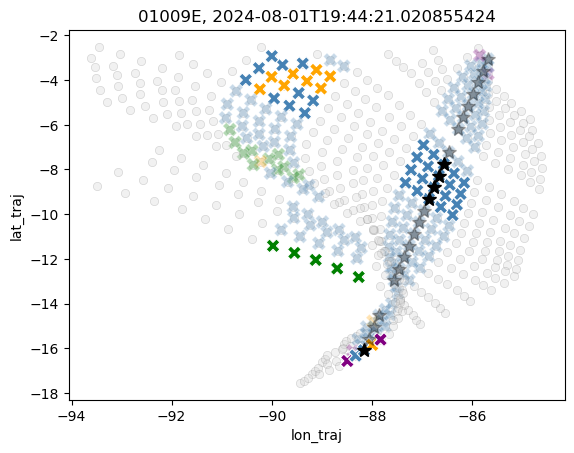

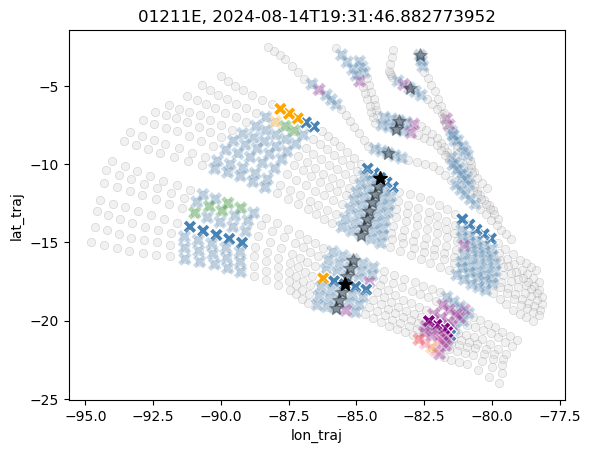

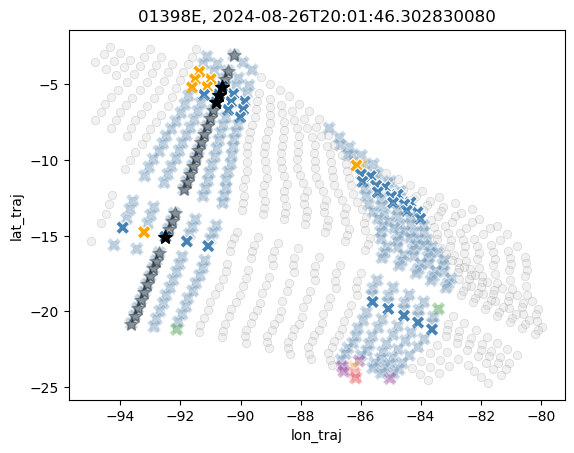

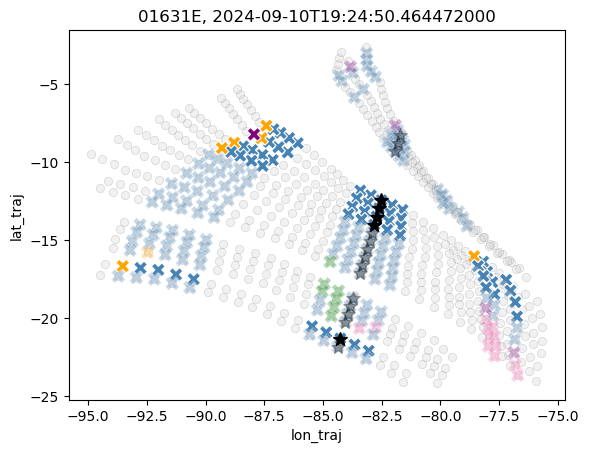

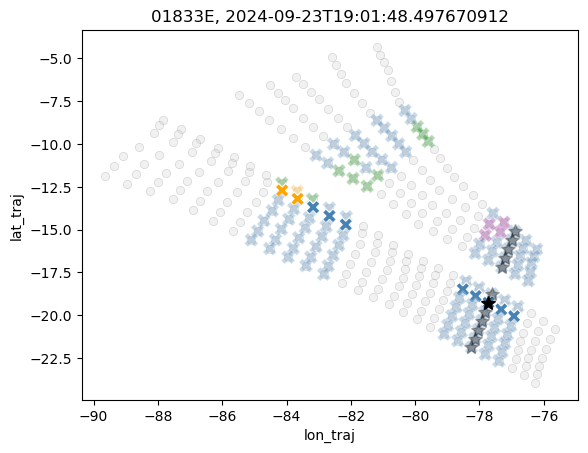

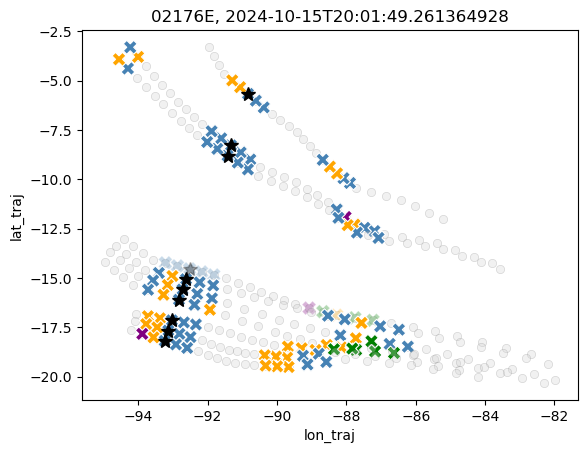

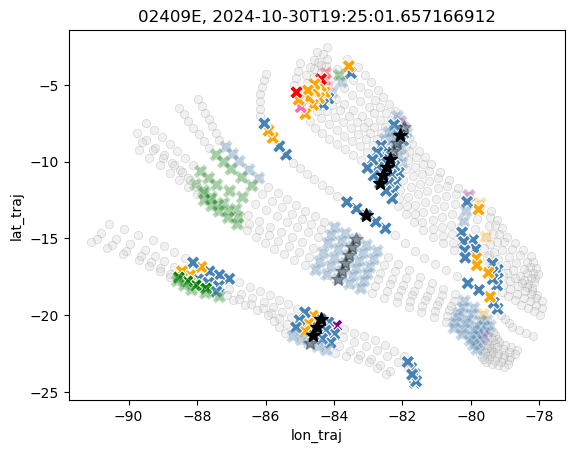

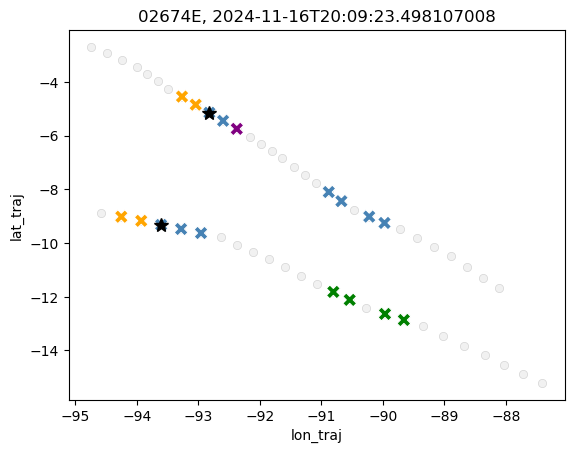

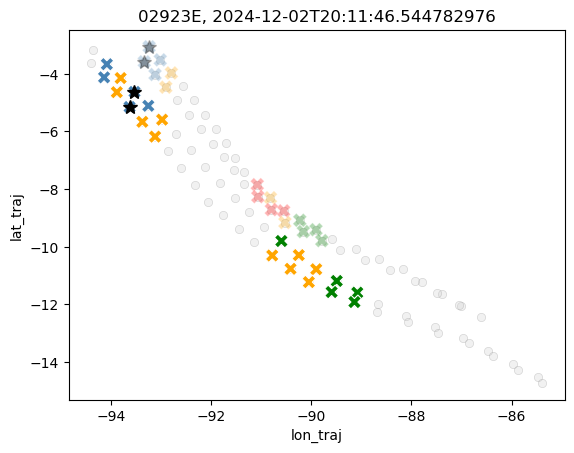

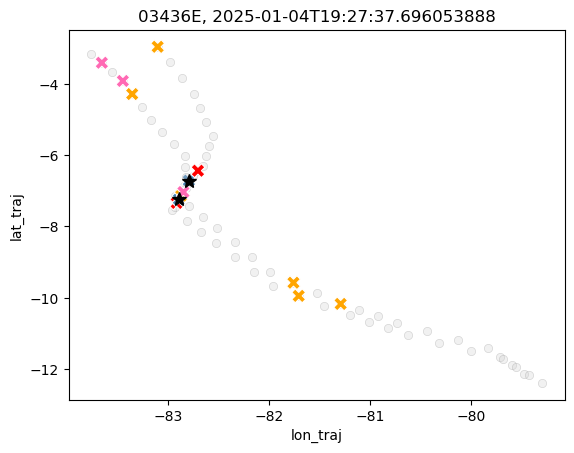

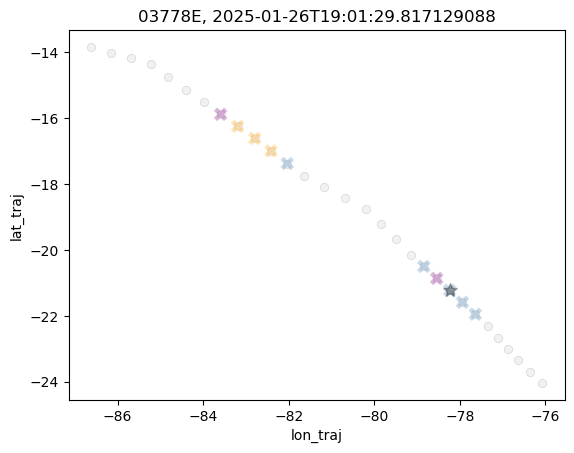

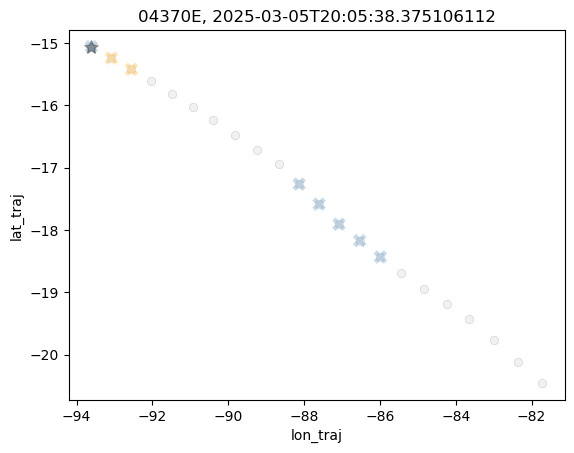

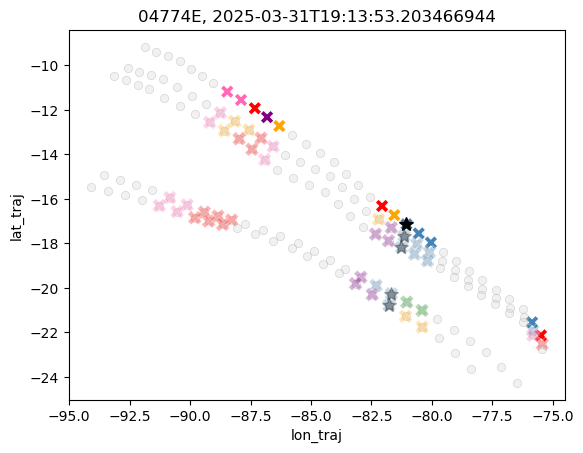

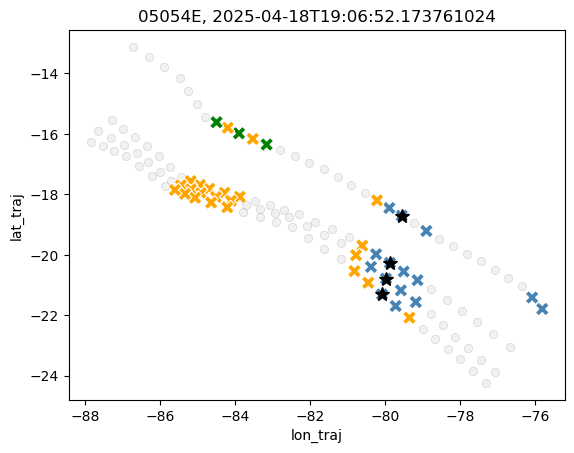

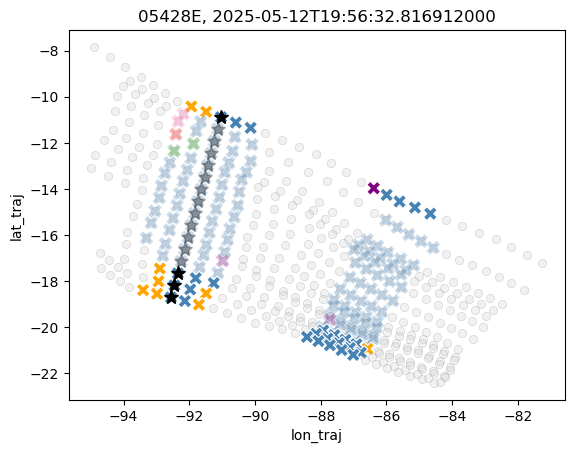

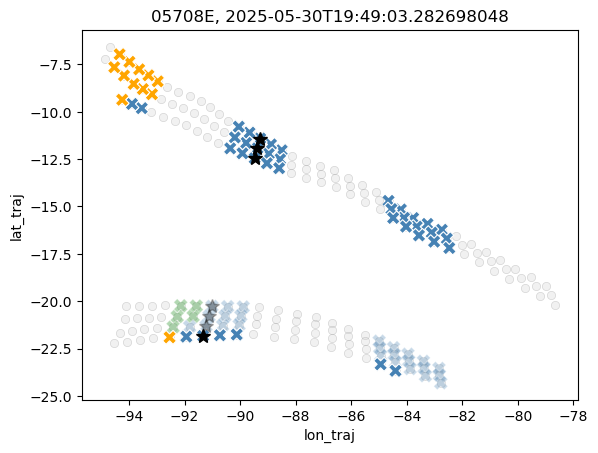

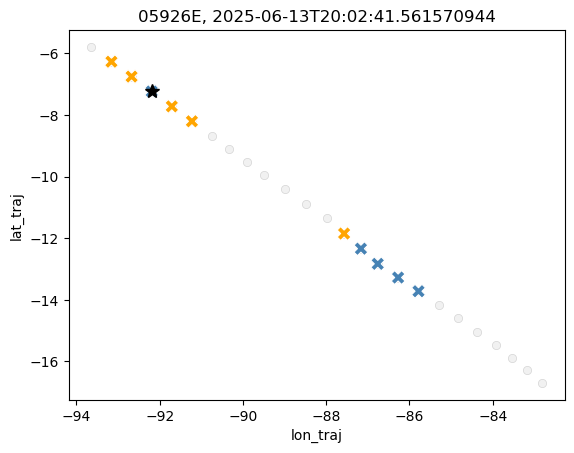

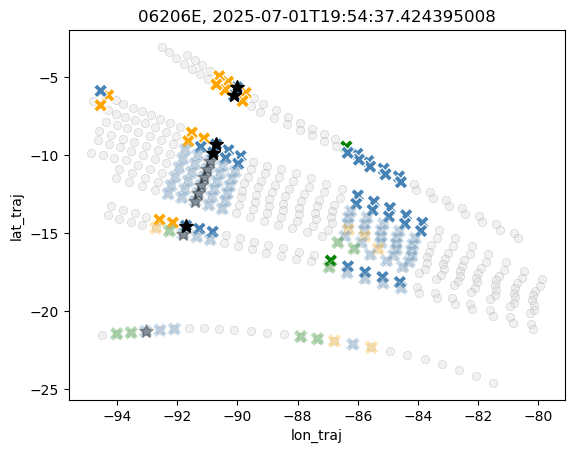

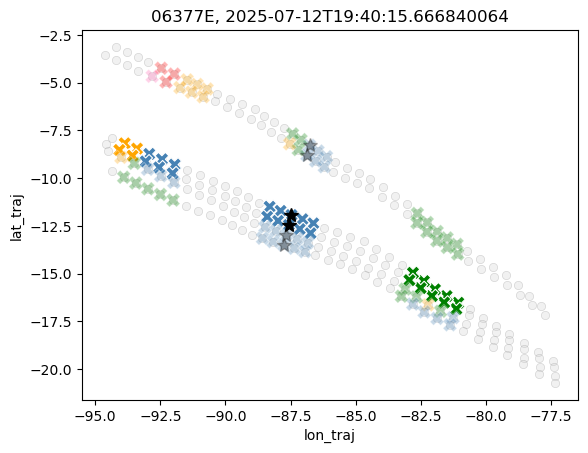

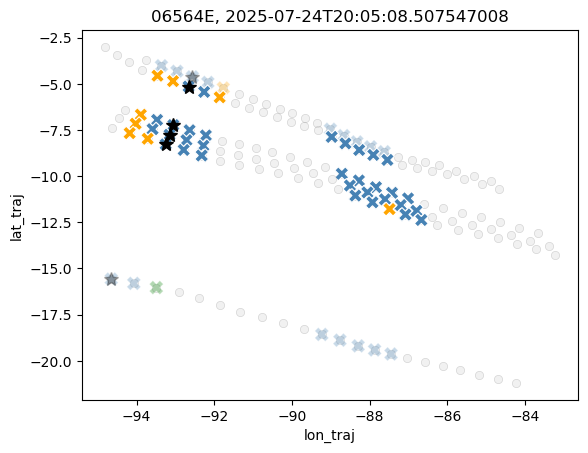

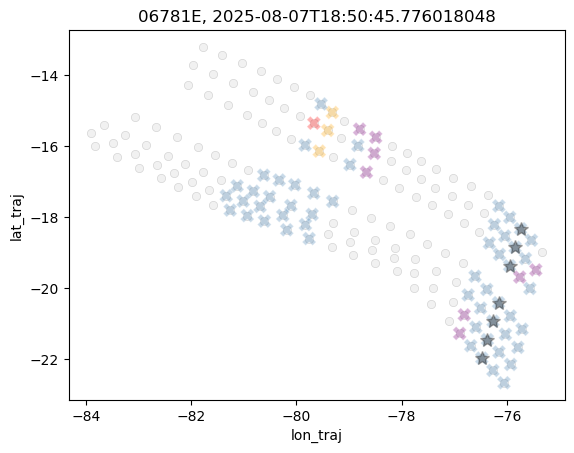

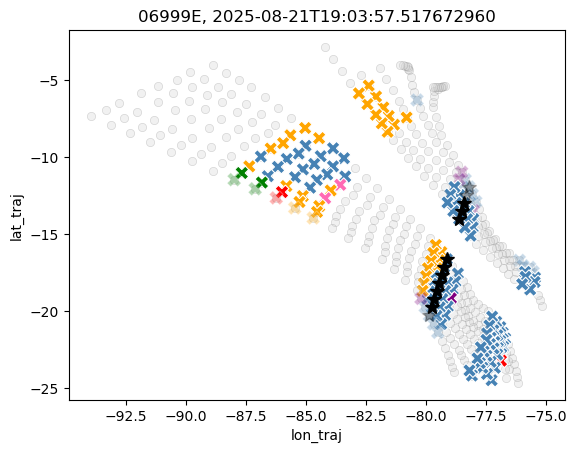

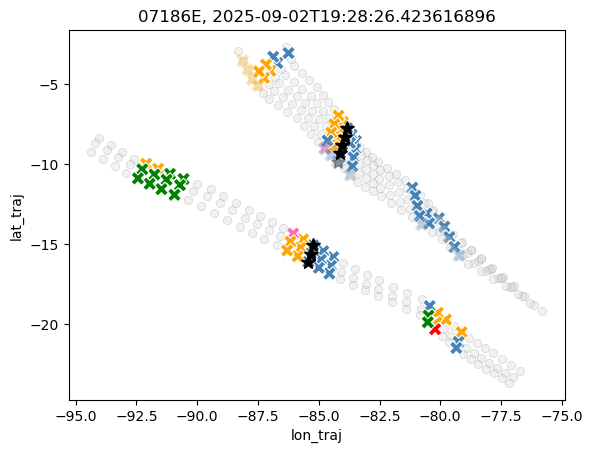

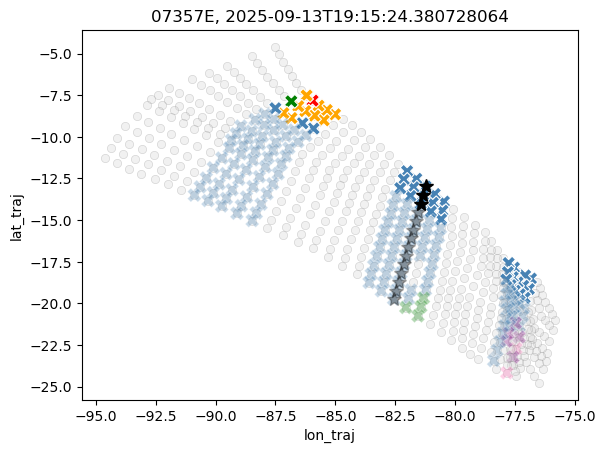

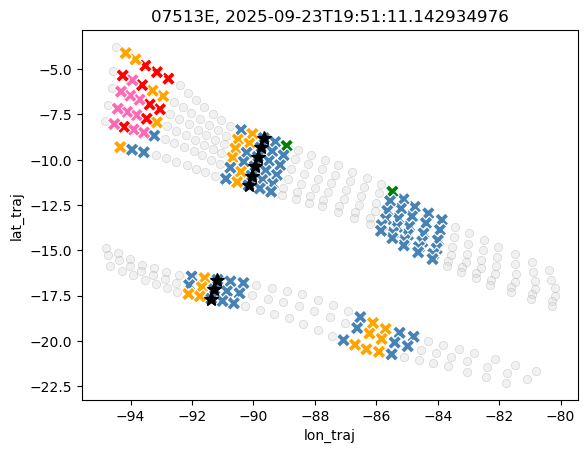

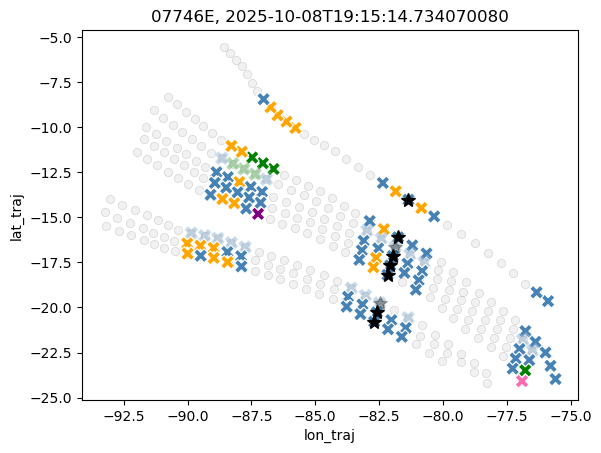

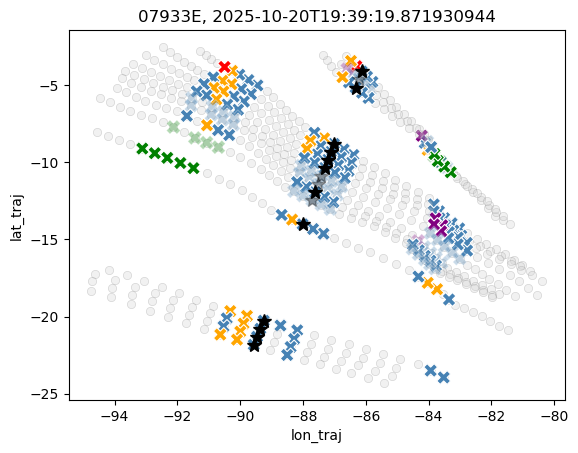

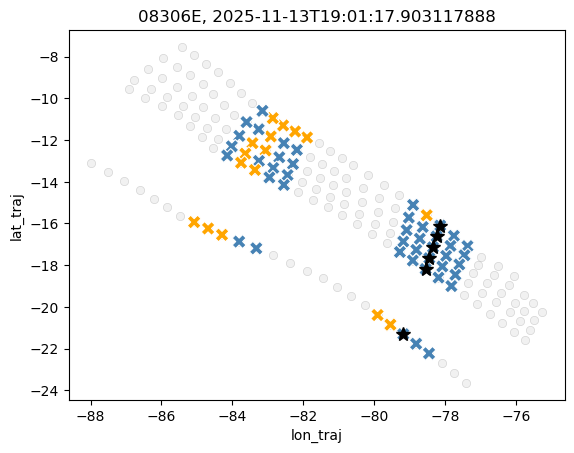

In [11]:
palette_goes_cats = {0: 'purple', 1: 'steelblue', 2: 'green', 3: 'orange', 4: 'red', 5: 'hotpink', np.nan: 'grey'}

ds_to_check = bt_cd_forward_from_c #bt_cd_back_from_d

for orbit in np.unique(ds_to_check.orbit)[::10]:
    bt_orbit = ds_to_check.where(ds_to_check.orbit == orbit, drop=True)
    for i in range(len(bt_orbit.time_startpoint)):
        tmp = bt_orbit.isel(time_startpoint=i)
        if tmp.transition_flag == False:
            # no transition detected
            alpha = 0.3
        else:
            # transition detected
            alpha = 1.0
        sns.scatterplot(data=tmp, x='lon_traj', y='lat_traj', color='lightgrey', alpha=0.3, edgecolor='Grey', legend=False)
        plt.plot([tmp.sel(timestep=0).lon_traj.values], [tmp.sel(timestep=0).lat_traj.values], color='black', marker='*', markersize=10, alpha=alpha)
        sns.scatterplot(data=tmp, x='lon_traj', y='lat_traj', hue='goes_cats', palette=palette_goes_cats, legend=False, s=100, marker='X', alpha=alpha)
    plt.title(f'{orbit}, {bt_orbit.time_startpoint.values[0]}')
    plt.show()

## add ACMCAP information

In [36]:
acmcap_dataset_filename = '/home/jmayer/ACI_research/Code/resources_mesoscale_structure/ACMCAP_judge_StCu.h5'
acmcap = pd.read_hdf(acmcap_dataset_filename, key='StCu')

# only need SEP data
acmcap = acmcap[acmcap.stratus_region_index == 2]

ds_acmcap = acmcap.to_xarray()
ds_acmcap = ds_acmcap.rename({'time_mid':'time_startpoint'})
ds_acmcap = ds_acmcap.swap_dims({'index':'time_startpoint'})
ds_acmcap = ds_acmcap.assign_coords({
    'time_startpoint': ds_acmcap.time_startpoint.values,
    'orbit': ('time_startpoint', ds_acmcap.orbit.values)})
ds_acmcap = ds_acmcap.drop_vars(['index'])

ds_acmcap['time_startpoint'] = ds_acmcap.time_startpoint.dt.round('0.1s')
ds_acmcap = ds_acmcap.assign_coords({'timestep': ('timestep', [0])})

ds_acmcap

<xarray.Dataset> Size: 11MB
Dimensions:                               (time_startpoint: 12979, timestep: 1)
Coordinates:
    orbit                                 (time_startpoint) object 104kB '010...
  * time_startpoint                       (time_startpoint) datetime64[ns] 104kB ...
  * timestep                              (timestep) int64 8B 0
Data variables: (12/106)
    scene_id                              (time_startpoint) int64 104kB 25868...
    stratus_region_index                  (time_startpoint) int64 104kB 2 ... 2
    along_track_mid                       (time_startpoint) float64 104kB 128...
    lon_mid                               (time_startpoint) float64 104kB -85...
    lat_mid                               (time_startpoint) float64 104kB -3....
    lat_min                               (time_startpoint) float64 104kB -3....
    ...                                    ...
    rwc_cbh_perc75                        (time_startpoint) float64 104kB nan...
    rwc_cbh_perc95                        (time_startpoint) float64 104kB nan...
    rwc_cbh_perc05                        (time_startpoint) float64 104kB nan...
    rain_gini                             (time_startpoint) float64 104kB 0.0...
    rain_lcf                              (time_startpoint) float64 104kB 0.0...
    rain_n_clusters                       (time_startpoint) int64 104kB 0 ... 3

In [37]:
ds_acmcap['rain_fraction_no_zero'] = ds_acmcap['rain_fraction'].where(ds_acmcap['rain_fraction'] != 0, np.nan)
for var in ['cbh_m', 'cth_m', 'lwp', 'ER', 'Nd', 'rwp', 'rain_median_volume_diameter']:
    ds_acmcap[var+'_cv'] = ds_acmcap[var+'_std'] / ds_acmcap[var]
acmcap_climatology_median = ds_acmcap.where(ds_acmcap.cats.isin([1,3,4]), drop=True).groupby('cats').median()

/home/jmayer/miniconda3/envs/bt_env/lib/python3.13/site-packages/xarray/structure/concat.py:540: UserWarning: No index created for dimension cats because variable cats is not a coordinate. To create an index for cats, please first call `.set_coords('cats')` on this object.
  ds.expand_dims(dim_name, create_index_for_new_dim=create_index_for_new_dim)


In [14]:
bt_cd_forward_from_c['time_startpoint'] = bt_cd_forward_from_c.time_startpoint.dt.round('0.1s')

# Align datasets along common dimensions first
bt_aligned, acmcap_aligned = xr.align(bt_cd_forward_from_c, ds_acmcap, join='left')

# Then merge
bt_cd_forward_from_c = bt_aligned.merge(acmcap_aligned)

In [15]:
bt_cd_forward_from_c

<xarray.Dataset> Size: 20MB
Dimensions:                               (time_startpoint: 2679, timestep: 43)
Coordinates:
  * time_startpoint                       (time_startpoint) datetime64[ns] 21kB ...
  * timestep                              (timestep) int64 344B -42 -40 ... 42
    orbit                                 (time_startpoint) object 21kB '0100...
Data variables: (12/139)
    lat_traj                              (time_startpoint, timestep) float64 922kB ...
    lon_traj                              (time_startpoint, timestep) float64 922kB ...
    plev_traj                             (time_startpoint, timestep) float64 922kB ...
    datetime_traj                         (time_startpoint, timestep) datetime64[ns] 922kB ...
    goes_cats                             (time_startpoint, timestep) float64 922kB ...
    goes_cert                             (time_startpoint, timestep) float64 922kB ...
    ...                                    ...
    cth_m_cv                              (time_startpoint) float64 21kB 0.07...
    lwp_cv                                (time_startpoint) float64 21kB 0.58...
    ER_cv                                 (time_startpoint) float64 21kB 0.30...
    Nd_cv                                 (time_startpoint) float64 21kB 0.39...
    rwp_cv                                (time_startpoint) float64 21kB nan ...
    rain_median_volume_diameter_cv        (time_startpoint) float64 21kB nan ...

In [16]:
bt_cd_back_from_d['time_startpoint'] = bt_cd_back_from_d.time_startpoint.dt.round('0.1s')

# Align datasets along common dimensions first
bt_aligned, acmcap_aligned = xr.align(bt_cd_back_from_d, ds_acmcap, join='left')

# Then merge
bt_cd_back_from_d = bt_aligned.merge(acmcap_aligned)

In [17]:
bt_cd_back_from_d

<xarray.Dataset> Size: 36MB
Dimensions:                               (time_startpoint: 4811, timestep: 43)
Coordinates:
  * time_startpoint                       (time_startpoint) datetime64[ns] 38kB ...
  * timestep                              (timestep) int64 344B -42 -40 ... 42
    orbit                                 (time_startpoint) object 38kB '0100...
Data variables: (12/139)
    lat_traj                              (time_startpoint, timestep) float64 2MB ...
    lon_traj                              (time_startpoint, timestep) float64 2MB ...
    plev_traj                             (time_startpoint, timestep) float64 2MB ...
    datetime_traj                         (time_startpoint, timestep) datetime64[ns] 2MB ...
    goes_cats                             (time_startpoint, timestep) float64 2MB ...
    goes_cert                             (time_startpoint, timestep) float64 2MB ...
    ...                                    ...
    cth_m_cv                              (time_startpoint) float64 38kB 0.10...
    lwp_cv                                (time_startpoint) float64 38kB 0.91...
    ER_cv                                 (time_startpoint) float64 38kB 0.40...
    Nd_cv                                 (time_startpoint) float64 38kB 0.12...
    rwp_cv                                (time_startpoint) float64 38kB nan ...
    rain_median_volume_diameter_cv        (time_startpoint) float64 38kB nan ...

In [18]:
bt_cd_concat = xr.concat([bt_cd_forward_from_c, bt_cd_back_from_d], dim='time_startpoint')

In [19]:
bt_cd_concat

<xarray.Dataset> Size: 56MB
Dimensions:                               (time_startpoint: 7490, timestep: 43)
Coordinates:
  * time_startpoint                       (time_startpoint) datetime64[ns] 60kB ...
  * timestep                              (timestep) int64 344B -42 -40 ... 42
    orbit                                 (time_startpoint) object 60kB '0100...
Data variables: (12/139)
    lat_traj                              (time_startpoint, timestep) float64 3MB ...
    lon_traj                              (time_startpoint, timestep) float64 3MB ...
    plev_traj                             (time_startpoint, timestep) float64 3MB ...
    datetime_traj                         (time_startpoint, timestep) datetime64[ns] 3MB ...
    goes_cats                             (time_startpoint, timestep) float64 3MB ...
    goes_cert                             (time_startpoint, timestep) float64 3MB ...
    ...                                    ...
    cth_m_cv                              (time_startpoint) float64 60kB 0.07...
    lwp_cv                                (time_startpoint) float64 60kB 0.58...
    ER_cv                                 (time_startpoint) float64 60kB 0.30...
    Nd_cv                                 (time_startpoint) float64 60kB 0.39...
    rwp_cv                                (time_startpoint) float64 60kB nan ...
    rain_median_volume_diameter_cv        (time_startpoint) float64 60kB nan ...

### filter trajectories: cat_GOES == cat_MSI

In [20]:
# GOES CNN category at overpass should be the same as MSI category
bt_cd_concat = bt_cd_concat.where(bt_cd_concat.goes_cats.sel(timestep=0).drop('timestep') == bt_cd_concat.cats, drop=True)

/tmp/ipykernel_2816320/2175052341.py:2: DeprecationWarning: dropping variables using `drop` is deprecated; use drop_vars.
  bt_cd_concat = bt_cd_concat.where(bt_cd_concat.goes_cats.sel(timestep=0).drop('timestep') == bt_cd_concat.cats, drop=True)


In [21]:
bt_cd_concat

<xarray.Dataset> Size: 34MB
Dimensions:                               (time_startpoint: 4478, timestep: 43)
Coordinates:
  * time_startpoint                       (time_startpoint) datetime64[ns] 36kB ...
  * timestep                              (timestep) int64 344B -42 -40 ... 42
    orbit                                 (time_startpoint) object 36kB '0100...
Data variables: (12/139)
    lat_traj                              (time_startpoint, timestep) float64 2MB ...
    lon_traj                              (time_startpoint, timestep) float64 2MB ...
    plev_traj                             (time_startpoint, timestep) float64 2MB ...
    datetime_traj                         (time_startpoint, timestep) datetime64[ns] 2MB ...
    goes_cats                             (time_startpoint, timestep) float64 2MB ...
    goes_cert                             (time_startpoint, timestep) float64 2MB ...
    ...                                    ...
    cth_m_cv                              (time_startpoint) float64 36kB 0.09...
    lwp_cv                                (time_startpoint) float64 36kB 0.53...
    ER_cv                                 (time_startpoint) float64 36kB 0.22...
    Nd_cv                                 (time_startpoint) float64 36kB 0.30...
    rwp_cv                                (time_startpoint) float64 36kB 8.77...
    rain_median_volume_diameter_cv        (time_startpoint) float64 36kB 0.19...

In [22]:
bt_cd_concat.where(bt_cd_concat.transition_flag == True, drop=True)

<xarray.Dataset> Size: 11MB
Dimensions:                               (time_startpoint: 1480, timestep: 43)
Coordinates:
  * time_startpoint                       (time_startpoint) datetime64[ns] 12kB ...
  * timestep                              (timestep) int64 344B -42 -40 ... 42
    orbit                                 (time_startpoint) object 12kB '0100...
Data variables: (12/139)
    lat_traj                              (time_startpoint, timestep) float64 509kB ...
    lon_traj                              (time_startpoint, timestep) float64 509kB ...
    plev_traj                             (time_startpoint, timestep) float64 509kB ...
    datetime_traj                         (time_startpoint, timestep) datetime64[ns] 509kB ...
    goes_cats                             (time_startpoint, timestep) float64 509kB ...
    goes_cert                             (time_startpoint, timestep) float64 509kB ...
    ...                                    ...
    cth_m_cv                              (time_startpoint) float64 12kB 0.13...
    lwp_cv                                (time_startpoint) float64 12kB 0.88...
    ER_cv                                 (time_startpoint) float64 12kB 0.45...
    Nd_cv                                 (time_startpoint) float64 12kB 0.08...
    rwp_cv                                (time_startpoint) float64 12kB nan ...
    rain_median_volume_diameter_cv        (time_startpoint) float64 12kB nan ...

In [23]:
bt_cd_concat.where((bt_cd_concat.transition_flag == True) & (bt_cd_concat.cats == 1), drop=True)

<xarray.Dataset> Size: 3MB
Dimensions:                               (time_startpoint: 456, timestep: 43)
Coordinates:
  * time_startpoint                       (time_startpoint) datetime64[ns] 4kB ...
  * timestep                              (timestep) int64 344B -42 -40 ... 42
    orbit                                 (time_startpoint) object 4kB '01009...
Data variables: (12/139)
    lat_traj                              (time_startpoint, timestep) float64 157kB ...
    lon_traj                              (time_startpoint, timestep) float64 157kB ...
    plev_traj                             (time_startpoint, timestep) float64 157kB ...
    datetime_traj                         (time_startpoint, timestep) datetime64[ns] 157kB ...
    goes_cats                             (time_startpoint, timestep) float64 157kB ...
    goes_cert                             (time_startpoint, timestep) float64 157kB ...
    ...                                    ...
    cth_m_cv                              (time_startpoint) float64 4kB 0.133...
    lwp_cv                                (time_startpoint) float64 4kB 0.886...
    ER_cv                                 (time_startpoint) float64 4kB 0.458...
    Nd_cv                                 (time_startpoint) float64 4kB 0.083...
    rwp_cv                                (time_startpoint) float64 4kB nan ....
    rain_median_volume_diameter_cv        (time_startpoint) float64 4kB nan ....

In [24]:
bt_cd_concat.where((bt_cd_concat.transition_flag == True) & (bt_cd_concat.cats.isin([3,4])), drop=True)

<xarray.Dataset> Size: 8MB
Dimensions:                               (time_startpoint: 1024, timestep: 43)
Coordinates:
  * time_startpoint                       (time_startpoint) datetime64[ns] 8kB ...
  * timestep                              (timestep) int64 344B -42 -40 ... 42
    orbit                                 (time_startpoint) object 8kB '01009...
Data variables: (12/139)
    lat_traj                              (time_startpoint, timestep) float64 352kB ...
    lon_traj                              (time_startpoint, timestep) float64 352kB ...
    plev_traj                             (time_startpoint, timestep) float64 352kB ...
    datetime_traj                         (time_startpoint, timestep) datetime64[ns] 352kB ...
    goes_cats                             (time_startpoint, timestep) float64 352kB ...
    goes_cert                             (time_startpoint, timestep) float64 352kB ...
    ...                                    ...
    cth_m_cv                              (time_startpoint) float64 8kB 0.155...
    lwp_cv                                (time_startpoint) float64 8kB 2.534...
    ER_cv                                 (time_startpoint) float64 8kB 0.641...
    Nd_cv                                 (time_startpoint) float64 8kB 0.434...
    rwp_cv                                (time_startpoint) float64 8kB 1.388...
    rain_median_volume_diameter_cv        (time_startpoint) float64 8kB 0.393...

## filter transitions: only transitions that stay D or C after the transition

In [46]:
bt_cd = bt_cd_concat.where(bt_cd_concat.transition_flag == True, drop=True)

In [78]:
bt_cd_filtered = bt_cd.copy(deep=True) 

for i in range(len(bt_cd.time_startpoint)):
    tmp = bt_cd.isel(time_startpoint=i)
    goes_cats_after_trans = tmp.goes_cats.sel(timestep = slice(tmp.transition_timestep, None)).dropna('timestep')
    stays_d_or_c = goes_cats_after_trans.isin([3,4,5]).all()
    enough_datapoints_after_trans = (goes_cats_after_trans.notnull().sum() >= 2)
    if not stays_d_or_c or not enough_datapoints_after_trans:
        bt_cd_filtered = bt_cd_filtered.where(bt_cd_filtered.time_startpoint != tmp.time_startpoint, drop=True)


In [65]:
tmp

<xarray.Dataset> Size: 8kB
Dimensions:                               (timestep: 43)
Coordinates:
    time_startpoint                       datetime64[ns] 8B 2024-08-01T19:45:...
  * timestep                              (timestep) int64 344B -42 -40 ... 42
    orbit                                 object 8B '01009E'
Data variables: (12/139)
    lat_traj                              (timestep) float64 344B nan ... nan
    lon_traj                              (timestep) float64 344B nan ... nan
    plev_traj                             (timestep) float64 344B nan ... nan
    datetime_traj                         (timestep) datetime64[ns] 344B NaT ...
    goes_cats                             (timestep) float64 344B nan ... nan
    goes_cert                             (timestep) float64 344B nan ... nan
    ...                                    ...
    cth_m_cv                              float64 8B 0.1331
    lwp_cv                                float64 8B 0.8862
    ER_cv                                 float64 8B 0.4586
    Nd_cv                                 float64 8B 0.08356
    rwp_cv                                float64 8B nan
    rain_median_volume_diameter_cv        float64 8B nan

In [72]:
tmp.transition_timestep

<xarray.DataArray 'transition_timestep' ()> Size: 8B
array(20.)
Coordinates:
    time_startpoint  datetime64[ns] 8B 2024-08-01T19:45:33.600000
    orbit            object 8B '01009E'
Attributes:
    description:  Timestep where transition from open to stratiform occurs (t...

In [77]:
bt_cd.isel(time_startpoint=0).goes_cats.sel(timestep=slice(18,None))

<xarray.DataArray 'goes_cats' (timestep: 13)> Size: 104B
array([nan,  3.,  3.,  1., nan, nan, nan, nan, nan, nan, nan, nan, nan])
Coordinates:
    time_startpoint  datetime64[ns] 8B 2024-08-01T19:45:33.600000
  * timestep         (timestep) int64 104B 18 20 22 24 26 28 ... 34 36 38 40 42
    orbit            object 8B '01009E'

In [80]:
goes_cats_after_trans

<xarray.DataArray 'goes_cats' (timestep: 3)> Size: 24B
array([1., 3., 3.])
Coordinates:
    time_startpoint  datetime64[ns] 8B 2025-11-17T20:10:09.500000
  * timestep         (timestep) int64 24B -4 -2 0
    orbit            object 8B '08369E'

In [81]:
goes_cats_after_trans.dropna('timestep').isin([3,4,5]).all()

<xarray.DataArray 'goes_cats' ()> Size: 1B
array(False)
Coordinates:
    time_startpoint  datetime64[ns] 8B 2025-11-17T20:10:09.500000
    orbit            object 8B '08369E'

In [85]:
tmp.goes_cats.sel(timestep = slice(tmp.transition_timestep-20, None))

<xarray.DataArray 'goes_cats' (timestep: 34)> Size: 272B
array([ 1.,  1.,  3., nan, nan, nan, nan, nan, nan, nan,  1.,  3.,  3.,
       nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan,
       nan, nan, nan, nan, nan, nan, nan, nan])
Coordinates:
    time_startpoint  datetime64[ns] 8B 2025-11-17T20:10:09.500000
  * timestep         (timestep) int64 272B -24 -22 -20 -18 -16 ... 36 38 40 42
    orbit            object 8B '08369E'

In [83]:
bt_cd_filtered

<xarray.Dataset> Size: 2MB
Dimensions:                               (time_startpoint: 238, timestep: 43)
Coordinates:
  * time_startpoint                       (time_startpoint) datetime64[ns] 2kB ...
  * timestep                              (timestep) int64 344B -42 -40 ... 42
    orbit                                 (time_startpoint) object 2kB '01040...
Data variables: (12/139)
    lat_traj                              (time_startpoint, timestep) float64 82kB ...
    lon_traj                              (time_startpoint, timestep) float64 82kB ...
    plev_traj                             (time_startpoint, timestep) float64 82kB ...
    datetime_traj                         (time_startpoint, timestep) datetime64[ns] 82kB ...
    goes_cats                             (time_startpoint, timestep) float64 82kB ...
    goes_cert                             (time_startpoint, timestep) float64 82kB ...
    ...                                    ...
    cth_m_cv                              (time_startpoint) float64 2kB 0.064...
    lwp_cv                                (time_startpoint) float64 2kB 0.371...
    ER_cv                                 (time_startpoint) float64 2kB 0.205...
    Nd_cv                                 (time_startpoint) float64 2kB 0.512...
    rwp_cv                                (time_startpoint) float64 2kB 1.486...
    rain_median_volume_diameter_cv        (time_startpoint) float64 2kB 0.050...

In [64]:
bt_cd

<xarray.Dataset> Size: 11MB
Dimensions:                               (time_startpoint: 1480, timestep: 43)
Coordinates:
  * time_startpoint                       (time_startpoint) datetime64[ns] 12kB ...
  * timestep                              (timestep) int64 344B -42 -40 ... 42
    orbit                                 (time_startpoint) object 12kB '0100...
Data variables: (12/139)
    lat_traj                              (time_startpoint, timestep) float64 509kB ...
    lon_traj                              (time_startpoint, timestep) float64 509kB ...
    plev_traj                             (time_startpoint, timestep) float64 509kB ...
    datetime_traj                         (time_startpoint, timestep) datetime64[ns] 509kB ...
    goes_cats                             (time_startpoint, timestep) float64 509kB ...
    goes_cert                             (time_startpoint, timestep) float64 509kB ...
    ...                                    ...
    cth_m_cv                              (time_startpoint) float64 12kB 0.13...
    lwp_cv                                (time_startpoint) float64 12kB 0.88...
    ER_cv                                 (time_startpoint) float64 12kB 0.45...
    Nd_cv                                 (time_startpoint) float64 12kB 0.08...
    rwp_cv                                (time_startpoint) float64 12kB nan ...
    rain_median_volume_diameter_cv        (time_startpoint) float64 12kB nan ...

## plots: occurrence of transitions

In [25]:
sns.set_context('talk', font_scale=1.)
sns.set_style('white')

/tmp/ipykernel_2816320/1685673911.py:12: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title='Orbit', bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=7, title_fontsize=10)


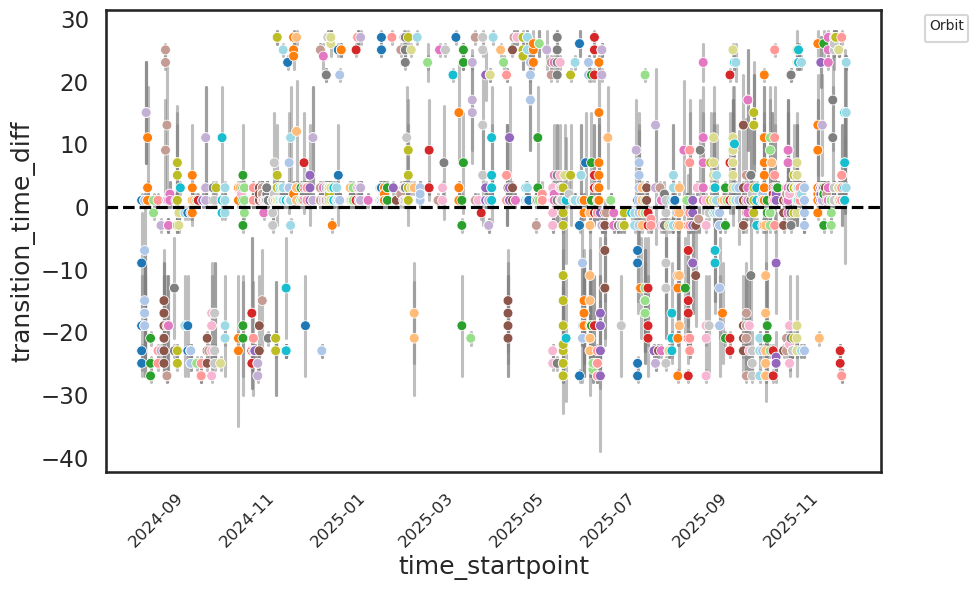

In [26]:
plt.figure(figsize=(10,6))
sns.scatterplot(data = bt_cd_concat, x='time_startpoint', y='transition_time_diff', hue='orbit', palette='tab20', legend=False, s=50)
plt.xticks(rotation=45, fontsize=12, ha='right')
# add whiskers for uncertainty
for i in range(len(bt_cd_concat.time_startpoint)):
    if not pd.isna(bt_cd_concat.transition_time_diff.values[i]):
        plt.plot([bt_cd_concat.time_startpoint.values[i], bt_cd_concat.time_startpoint.values[i]], 
                 [bt_cd_concat.transition_time_diff.values[i] - bt_cd_concat.transition_uncertainty.values[i],
                  bt_cd_concat.transition_time_diff.values[i] + bt_cd_concat.transition_uncertainty.values[i]], 
                 color='gray', alpha=0.5, zorder=0)
plt.axhline(0, color='black', linestyle='--')
plt.legend(title='Orbit', bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=7, title_fontsize=10)

Text(0.5, 0, 'time')

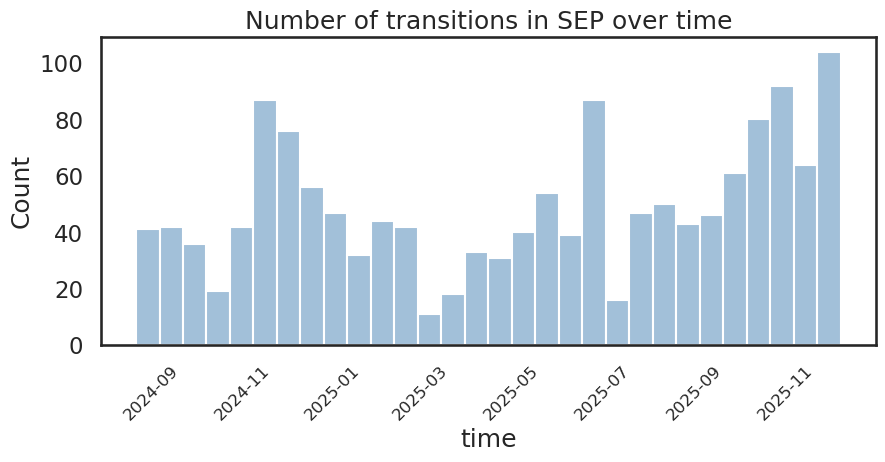

In [28]:
plt.figure(figsize=(10,4))
sns.histplot(data = bt_cd_concat.where((bt_cd_concat.transition_flag == True), drop=True), x='time_startpoint', bins=30, color='steelblue', alpha=0.5)
plt.xticks(rotation=45, fontsize=12, ha='right')
plt.title('Number of transitions in SEP over time')
plt.xlabel('time')

Text(0.5, 1.0, '(b) backward trajectories from open cells to transitions')

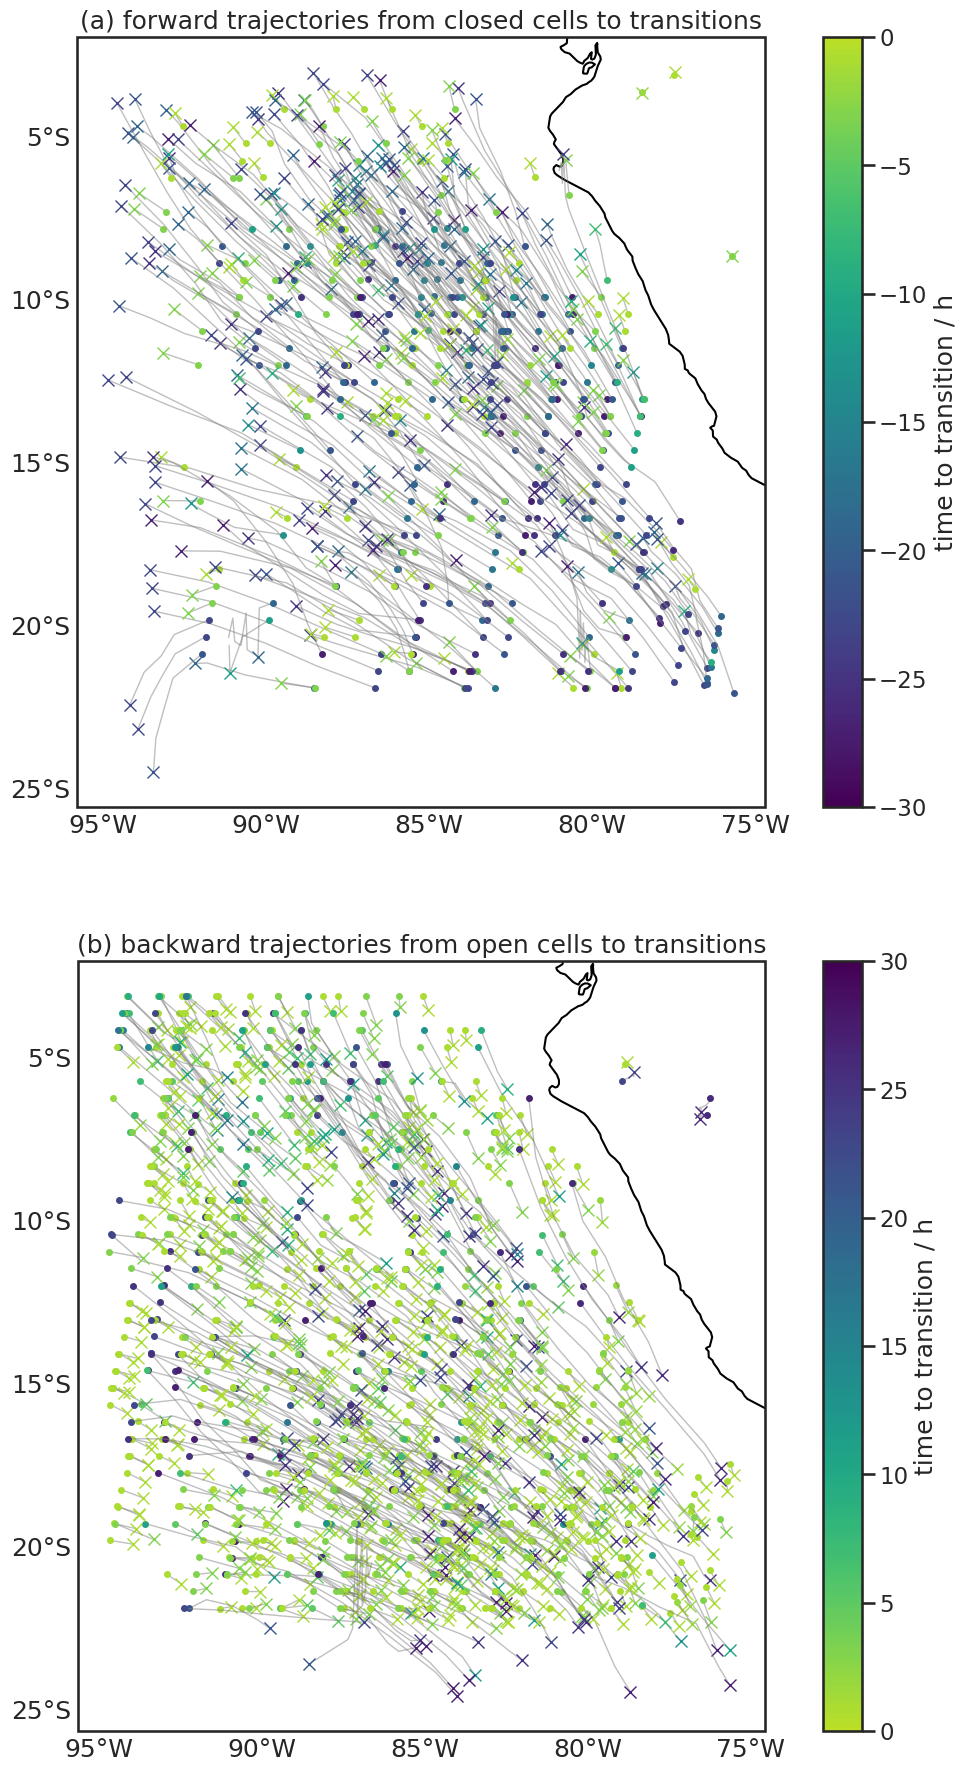

In [30]:
import matplotlib as mpl
import matplotlib.ticker as mticker
import cartopy.crs as ccrs

fig, (ax1,ax2) = plt.subplots(2,1, figsize=(15, 22), subplot_kw={'projection': ccrs.PlateCarree()})
for ax in [ax1, ax2]:
    ax.coastlines()
    gl = ax.gridlines(crs=ccrs.PlateCarree(), draw_labels=True)
    gl.top_labels = False
    gl.right_labels = False
    gl.xlines = False
    gl.ylines = False
    gl.xlocator = mticker.FixedLocator([-95, -90, -85, -80, -75])
    gl.ylocator = mticker.FixedLocator([-25, -20, -15, -10, -5])

ax=ax1
bt_co_forward_from_c_with_trans = bt_cd_concat.where((bt_cd_concat.transition_flag==True) & (bt_cd_concat.cats == 1), drop=True)
for startpoint in bt_co_forward_from_c_with_trans.time_startpoint.values:
    tmp = bt_co_forward_from_c_with_trans.sel(time_startpoint=startpoint).sel(timestep=slice(0,50)).sortby('timestep')
    #orbit = tmp.orbit_startpoint.values
    transition_timestep = tmp.transition_timestep.values
    tmp = tmp.sel(timestep=slice(0,transition_timestep+1))
    
    x_0 = tmp.sel(timestep=0).lon_traj.values.item()
    y_0 = tmp.sel(timestep=0).lat_traj.values.item()
    x_t = tmp.sel(timestep=transition_timestep).lon_traj.values.item()
    y_t = tmp.sel(timestep=transition_timestep).lat_traj.values.item()

    val = float(tmp.transition_time_diff.values) 
    norm = mpl.colors.Normalize(vmin=-30, vmax=0)
    cmap = plt.get_cmap("viridis")
    cmap = mpl.colors.LinearSegmentedColormap.from_list("viridis_cropped", cmap(np.linspace(0, 0.9, 256)))
    rgba = cmap(norm(val))

    sns.lineplot(ax=ax,x=tmp.lon_traj, y=tmp.lat_traj, color='grey', alpha=0.5, lw=1)
    ax.plot(x_0, y_0, marker='o',  ms=4, lw=0, color=rgba)
    ax.plot(x_t, y_t, marker='x', ms=8, lw=0, color=rgba)
    
    # sns.lineplot(x=tmp.lon_traj, y=tmp.lat_traj, color='gray', alpha=0.5)
    # plt.plot([tmp.sel(timestep=0).lon_traj.values], [tmp.sel(timestep=0).lat_traj.values], 'ko', ms=4)
    #plt.plot([tmp.sel(timestep=transition_timestep).lon_traj.values], [tmp.sel(timestep=transition_timestep).lat_traj.values], 'X', ms=7, color='black')
    #sns.scatterplot(data=tmp, x='lon_traj', y='lat_traj', hue='goes_cats', palette=palette_goes_cats, legend=False, s=50, marker='o')
#plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])
plt.colorbar(sm, ax=ax, label="time to transition / h")
ax.set_title('(a) forward trajectories from closed cells to transitions')

ax=ax2
bt_co_back_from_o_with_trans = bt_cd_concat.where((bt_cd_concat.transition_flag==True) & (bt_cd_concat.cats.isin([3,4])), drop=True)
for startpoint in bt_co_back_from_o_with_trans.time_startpoint.values:
    tmp = bt_co_back_from_o_with_trans.sel(time_startpoint=startpoint).sel(timestep=slice(-50,1)).sortby('timestep')
    #orbit = tmp.orbit_startpoint.values
    transition_timestep = tmp.transition_timestep.values
    tmp = tmp.sel(timestep=slice(transition_timestep,0))

    x_0 = tmp.sel(timestep=0).lon_traj.values.item()
    y_0 = tmp.sel(timestep=0).lat_traj.values.item()
    x_t = tmp.sel(timestep=transition_timestep).lon_traj.values.item()
    y_t = tmp.sel(timestep=transition_timestep).lat_traj.values.item()

    val = float(tmp.transition_time_diff.values) 
    norm = mpl.colors.Normalize(vmin=0, vmax=30)
    cmap = plt.get_cmap("viridis_r")
    cmap = mpl.colors.LinearSegmentedColormap.from_list("viridis_cropped", cmap(np.linspace(0.1, 1, 256)))
    rgba = cmap(norm(val))

    sns.lineplot(ax=ax, x=tmp.lon_traj, y=tmp.lat_traj, color='grey', alpha=0.5, lw=1)
    ax.plot(x_0, y_0, marker='o',  ms=4, lw=0, color=rgba)
    ax.plot(x_t, y_t, marker='x', ms=8, lw=0, color=rgba)
    
    #sns.lineplot(x=tmp.lon_traj, y=tmp.lat_traj, color='gray', alpha=0.5)
    #plt.plot([tmp.sel(timestep=0).lon_traj.values], [tmp.sel(timestep=0).lat_traj.values], 'ko', ms=4)
    #plt.plot([tmp.sel(timestep=transition_timestep).lon_traj.values], [tmp.sel(timestep=transition_timestep).lat_traj.values], 'X', ms=7, color='black')
sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])
plt.colorbar(sm, ax=ax, label="time to transition / h")
ax.set_title('(b) backward trajectories from open cells to transitions')

# CD transitions

## ACMCAP variables as function of time-to-transition

In [87]:
bt_cd_concat = bt_cd_filtered

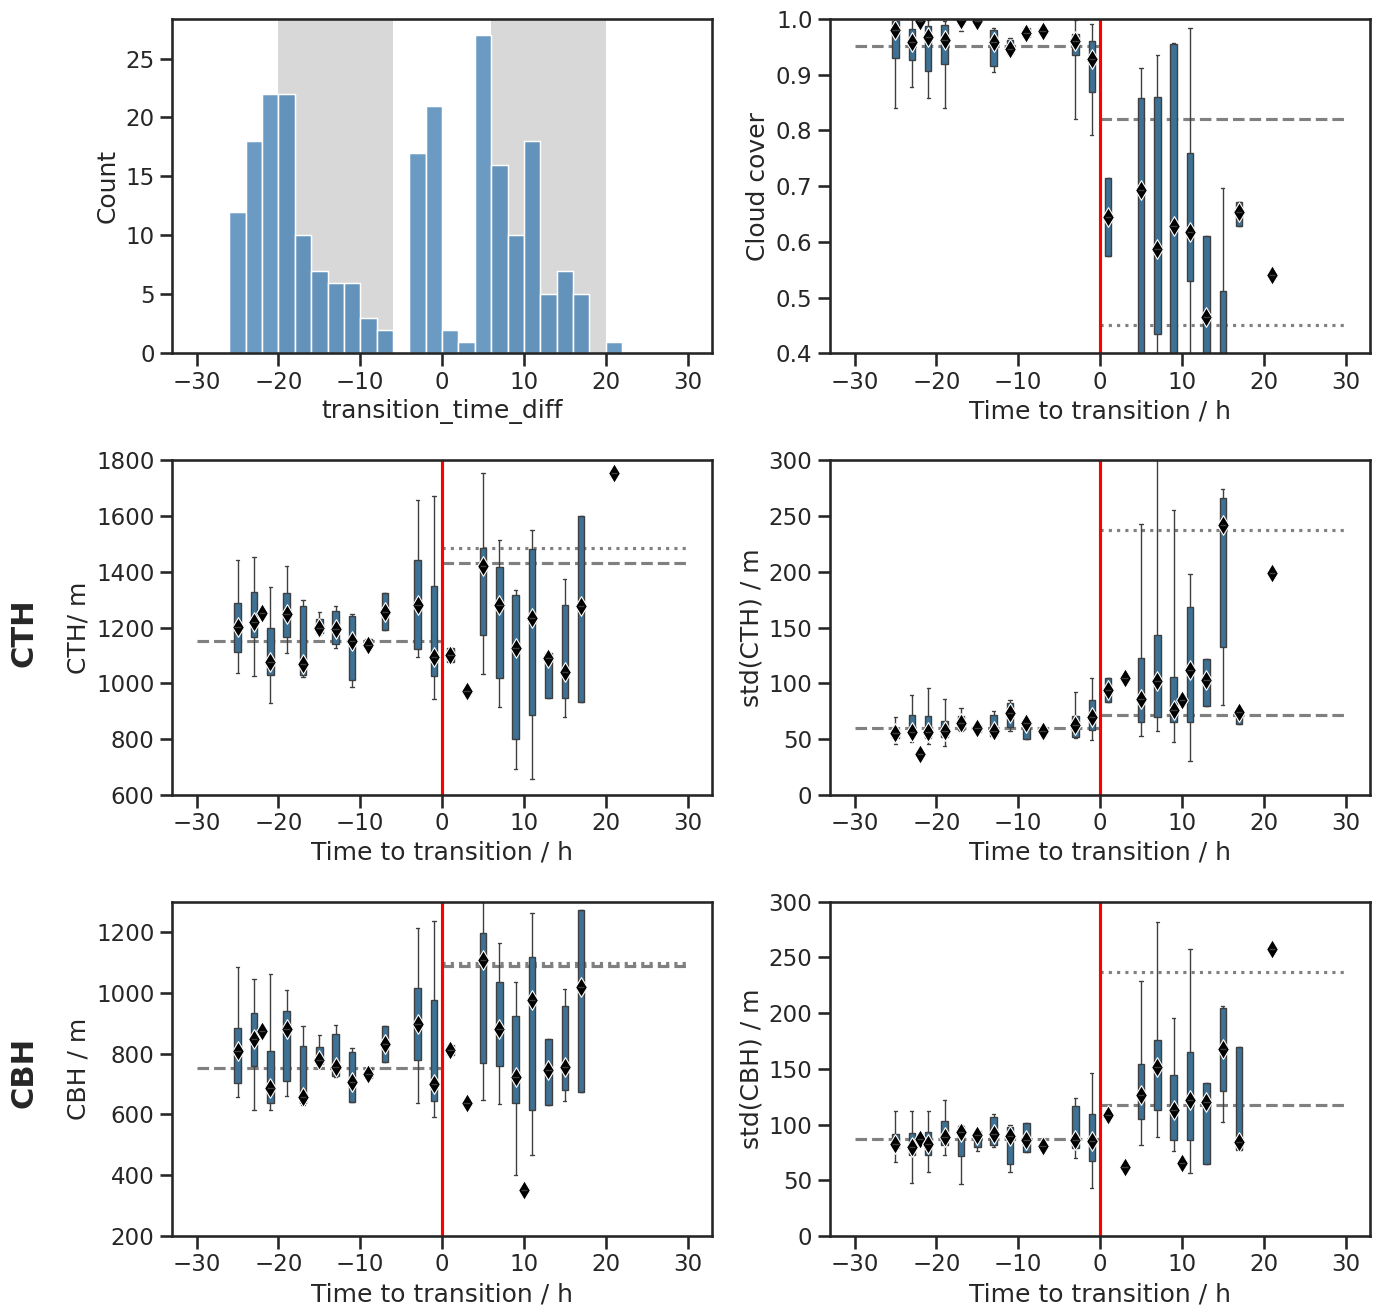

In [88]:
plot_params = {
    'no_plot': {},
    'cloud_cover': {'factor': 1, 'y_label': 'Cloud cover', 'y_lim': (0.4, 1), 'y_scale': 'linear'},
    'cth_m': {'factor': 1, 'y_label': 'CTH/ m', 'y_lim': (600, 1800), 'y_scale': 'linear'},
    'cth_m_std': {'factor': 1e0, 'y_label': 'std(CTH) / m', 'y_lim': (0, 300), 'y_scale': 'linear'},
    'cbh_m': {'factor': 1e0, 'y_label': 'CBH / m', 'y_lim': (200, 1300), 'y_scale': 'linear'},
    'cbh_m_std': {'factor': 1e0, 'y_label': 'std(CBH) / m', 'y_lim': (0, 300), 'y_scale': 'linear'},
}

sns.set_context('talk', font_scale=1.)
sns.set_style('white')
plt.rcParams['xtick.bottom'] = True
plt.rcParams['xtick.top'] = False
plt.rcParams['ytick.left'] = True
plt.rcParams['ytick.right'] = False

nrows = 3
fig, axs = plt.subplots(nrows, 2, figsize=(14, nrows*4.5))
axs = axs.flatten()

# add grey background for nighttime periods
axs[0].axvspan(-20, -6, color='grey', alpha=0.3, lw=0)
axs[0].axvspan(6, 20, color='grey', alpha=0.3, lw=0)
sns.histplot(ax=axs[0], data = bt_cd_concat, x='transition_time_diff', bins=np.linspace(-30, 30, 31), color='steelblue', alpha=0.8)
plt.xlabel('Time to transition / h')

for i, (var, params) in enumerate(plot_params.items()):
    plt.sca(axs[i])
    if var == 'no_plot':
        continue
    plt.hlines(acmcap_climatology_median[var].sel(cats=1)*params['factor'], xmin=-30, xmax=0, color='grey', linestyle='--')
    plt.hlines(acmcap_climatology_median[var].sel(cats=3)*params['factor'], xmin=0, xmax=30, color='grey', linestyle='--')
    plt.hlines(acmcap_climatology_median[var].sel(cats=4)*params['factor'], xmin=0, xmax=30, color='grey', linestyle=':')
    sns.boxplot(data = bt_cd_concat, x='transition_time_diff', y=bt_cd_concat[var]*params['factor'], whis=(5, 95), native_scale=True, showfliers=False, saturation=0.6)
    tmp = bt_cd_concat[['transition_time_diff', var]].groupby('transition_time_diff').median()
    sns.scatterplot(data=tmp, x='transition_time_diff', y=tmp[var]*params['factor'], color='black', marker='d', s=100, zorder=2)
    plt.yscale(params['y_scale'])
    plt.ylim(params['y_lim'])
    plt.xlabel('Time to transition / h')
    plt.ylabel(params['y_label'])
    plt.axvline(0, color='red', linestyle='-')

#axs[2].annotate('mean', xy=(0.4, 1.1), xycoords='axes fraction', fontsize=22, fontweight='bold')
#axs[3].annotate('std', xy=(0.45, 1.1), xycoords='axes fraction', fontsize=22, fontweight='bold')
for idx, text in enumerate(['','CTH','CBH']):
    axs[idx*2].annotate(text, xy=(-0.3, 0.4), xycoords='axes fraction', rotation=90, fontsize=22, fontweight='bold')
fig.tight_layout()

/home/jmayer/miniconda3/envs/bt_env/lib/python3.13/site-packages/xarray/structure/concat.py:540: UserWarning: No index created for dimension transition_time_diff because variable transition_time_diff is not a coordinate. To create an index for transition_time_diff, please first call `.set_coords('transition_time_diff')` on this object.
  ds.expand_dims(dim_name, create_index_for_new_dim=create_index_for_new_dim)
/home/jmayer/miniconda3/envs/bt_env/lib/python3.13/site-packages/xarray/structure/concat.py:540: UserWarning: No index created for dimension transition_time_diff because variable transition_time_diff is not a coordinate. To create an index for transition_time_diff, please first call `.set_coords('transition_time_diff')` on this object.
  ds.expand_dims(dim_name, create_index_for_new_dim=create_index_for_new_dim)
/home/jmayer/miniconda3/envs/bt_env/lib/python3.13/site-packages/xarray/structure/concat.py:540: UserWarning: No index created for dimension transition_time_diff becaus

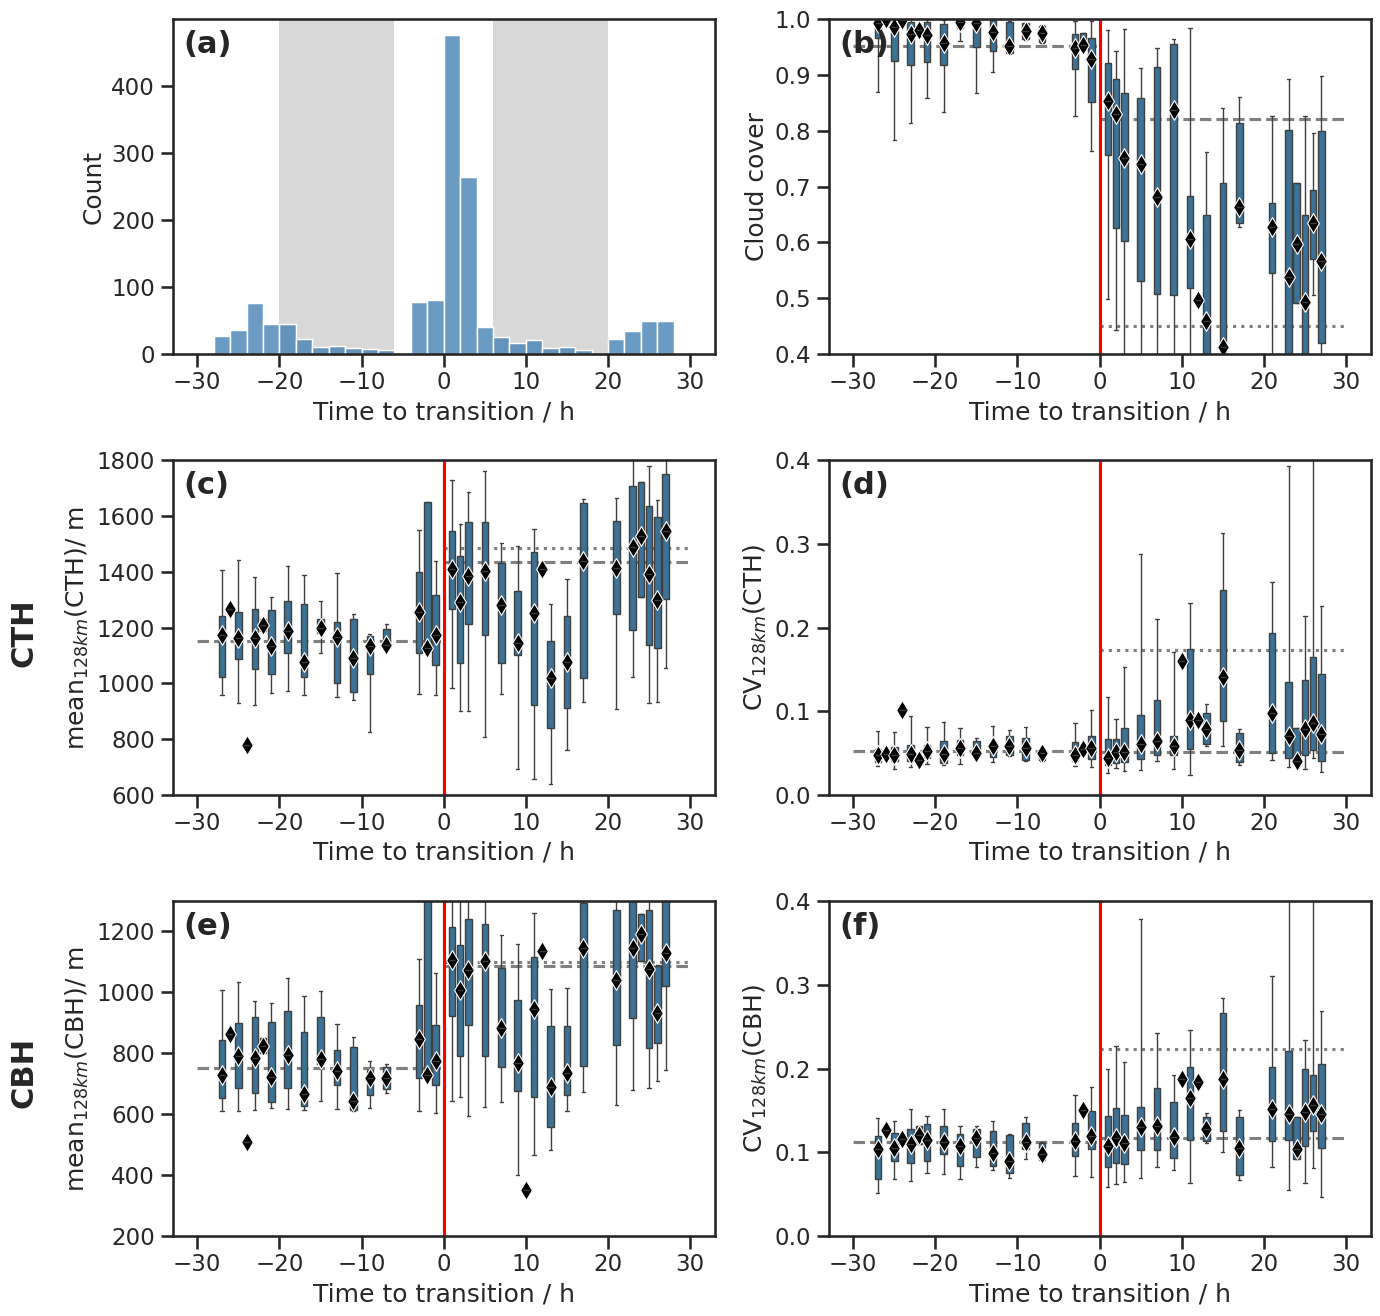

In [39]:
plot_params = {
    'no_plot': {},
    'cloud_cover': {'factor': 1, 'y_label': 'Cloud cover', 'y_lim': (0.4, 1), 'y_scale': 'linear'},
    'cth_m': {'factor': 1, 'y_label': 'mean$_{128km}$(CTH)/ m', 'y_lim': (600, 1800), 'y_scale': 'linear'},
    'cth_m_cv': {'factor': 1, 'y_label': 'CV$_{128km}$(CTH)', 'y_lim': (0, 0.4), 'y_scale': 'linear'},
    'cbh_m': {'factor': 1, 'y_label': 'mean$_{128km}$(CBH)/ m', 'y_lim': (200, 1300), 'y_scale': 'linear'},
    'cbh_m_cv': {'factor': 1, 'y_label': 'CV$_{128km}$(CBH)', 'y_lim': (0, 0.4), 'y_scale': 'linear'},
}

sns.set_context('talk', font_scale=1.)
sns.set_style('white')
plt.rcParams['xtick.bottom'] = True
plt.rcParams['xtick.top'] = False
plt.rcParams['ytick.left'] = True
plt.rcParams['ytick.right'] = False

nrows = 3
fig, axs = plt.subplots(nrows, 2, figsize=(14, nrows*4.5))
axs = axs.flatten()

# add grey background for nighttime periods
axs[0].axvspan(-20, -6, color='grey', alpha=0.3, lw=0)
axs[0].axvspan(6, 20, color='grey', alpha=0.3, lw=0)
sns.histplot(ax=axs[0], data = bt_cd_concat, x='transition_time_diff', bins=np.linspace(-30, 30, 31), color='steelblue', alpha=0.8)
axs[0].set_xlabel('Time to transition / h')

for i, (var, params) in enumerate(plot_params.items()):
    plt.sca(axs[i])
    if var == 'no_plot':
        continue
    plt.hlines(acmcap_climatology_median[var].sel(cats=1)*params['factor'], xmin=-30, xmax=0, color='grey', linestyle='--')
    plt.hlines(acmcap_climatology_median[var].sel(cats=3)*params['factor'], xmin=0, xmax=30, color='grey', linestyle='--')
    plt.hlines(acmcap_climatology_median[var].sel(cats=4)*params['factor'], xmin=0, xmax=30, color='grey', linestyle=':')
    sns.boxplot(data = bt_cd_concat, x='transition_time_diff', y=bt_cd_concat[var]*params['factor'], whis=(5, 95), native_scale=True, showfliers=False, saturation=0.6)
    tmp = bt_cd_concat[['transition_time_diff', var]].groupby('transition_time_diff').median()
    sns.scatterplot(data=tmp, x='transition_time_diff', y=tmp[var]*params['factor'], color='black', marker='d', s=100, zorder=2)
    plt.yscale(params['y_scale'])
    plt.ylim(params['y_lim'])
    plt.xlabel('Time to transition / h')
    plt.ylabel(params['y_label'])
    plt.axvline(0, color='red', linestyle='-')

#axs[2].annotate('mean', xy=(0.4, 1.1), xycoords='axes fraction', fontsize=22, fontweight='bold')
#axs[3].annotate('std', xy=(0.45, 1.1), xycoords='axes fraction', fontsize=22, fontweight='bold')
axs[0].annotate('(a)', xy=(0.02, 0.9), xycoords='axes fraction', fontsize=22, fontweight='bold')
axs[1].annotate('(b)', xy=(0.02, 0.9), xycoords='axes fraction', fontsize=22, fontweight='bold')
axs[2].annotate('(c)', xy=(0.02, 0.9), xycoords='axes fraction', fontsize=22, fontweight='bold')
axs[3].annotate('(d)', xy=(0.02, 0.9), xycoords='axes fraction', fontsize=22, fontweight='bold')
axs[4].annotate('(e)', xy=(0.02, 0.9), xycoords='axes fraction', fontsize=22, fontweight='bold')
axs[5].annotate('(f)', xy=(0.02, 0.9), xycoords='axes fraction', fontsize=22, fontweight='bold')
for idx, text in enumerate(['','CTH','CBH']):
    axs[idx*2].annotate(text, xy=(-0.3, 0.4), xycoords='axes fraction', rotation=90, fontsize=22, fontweight='bold')
fig.tight_layout()


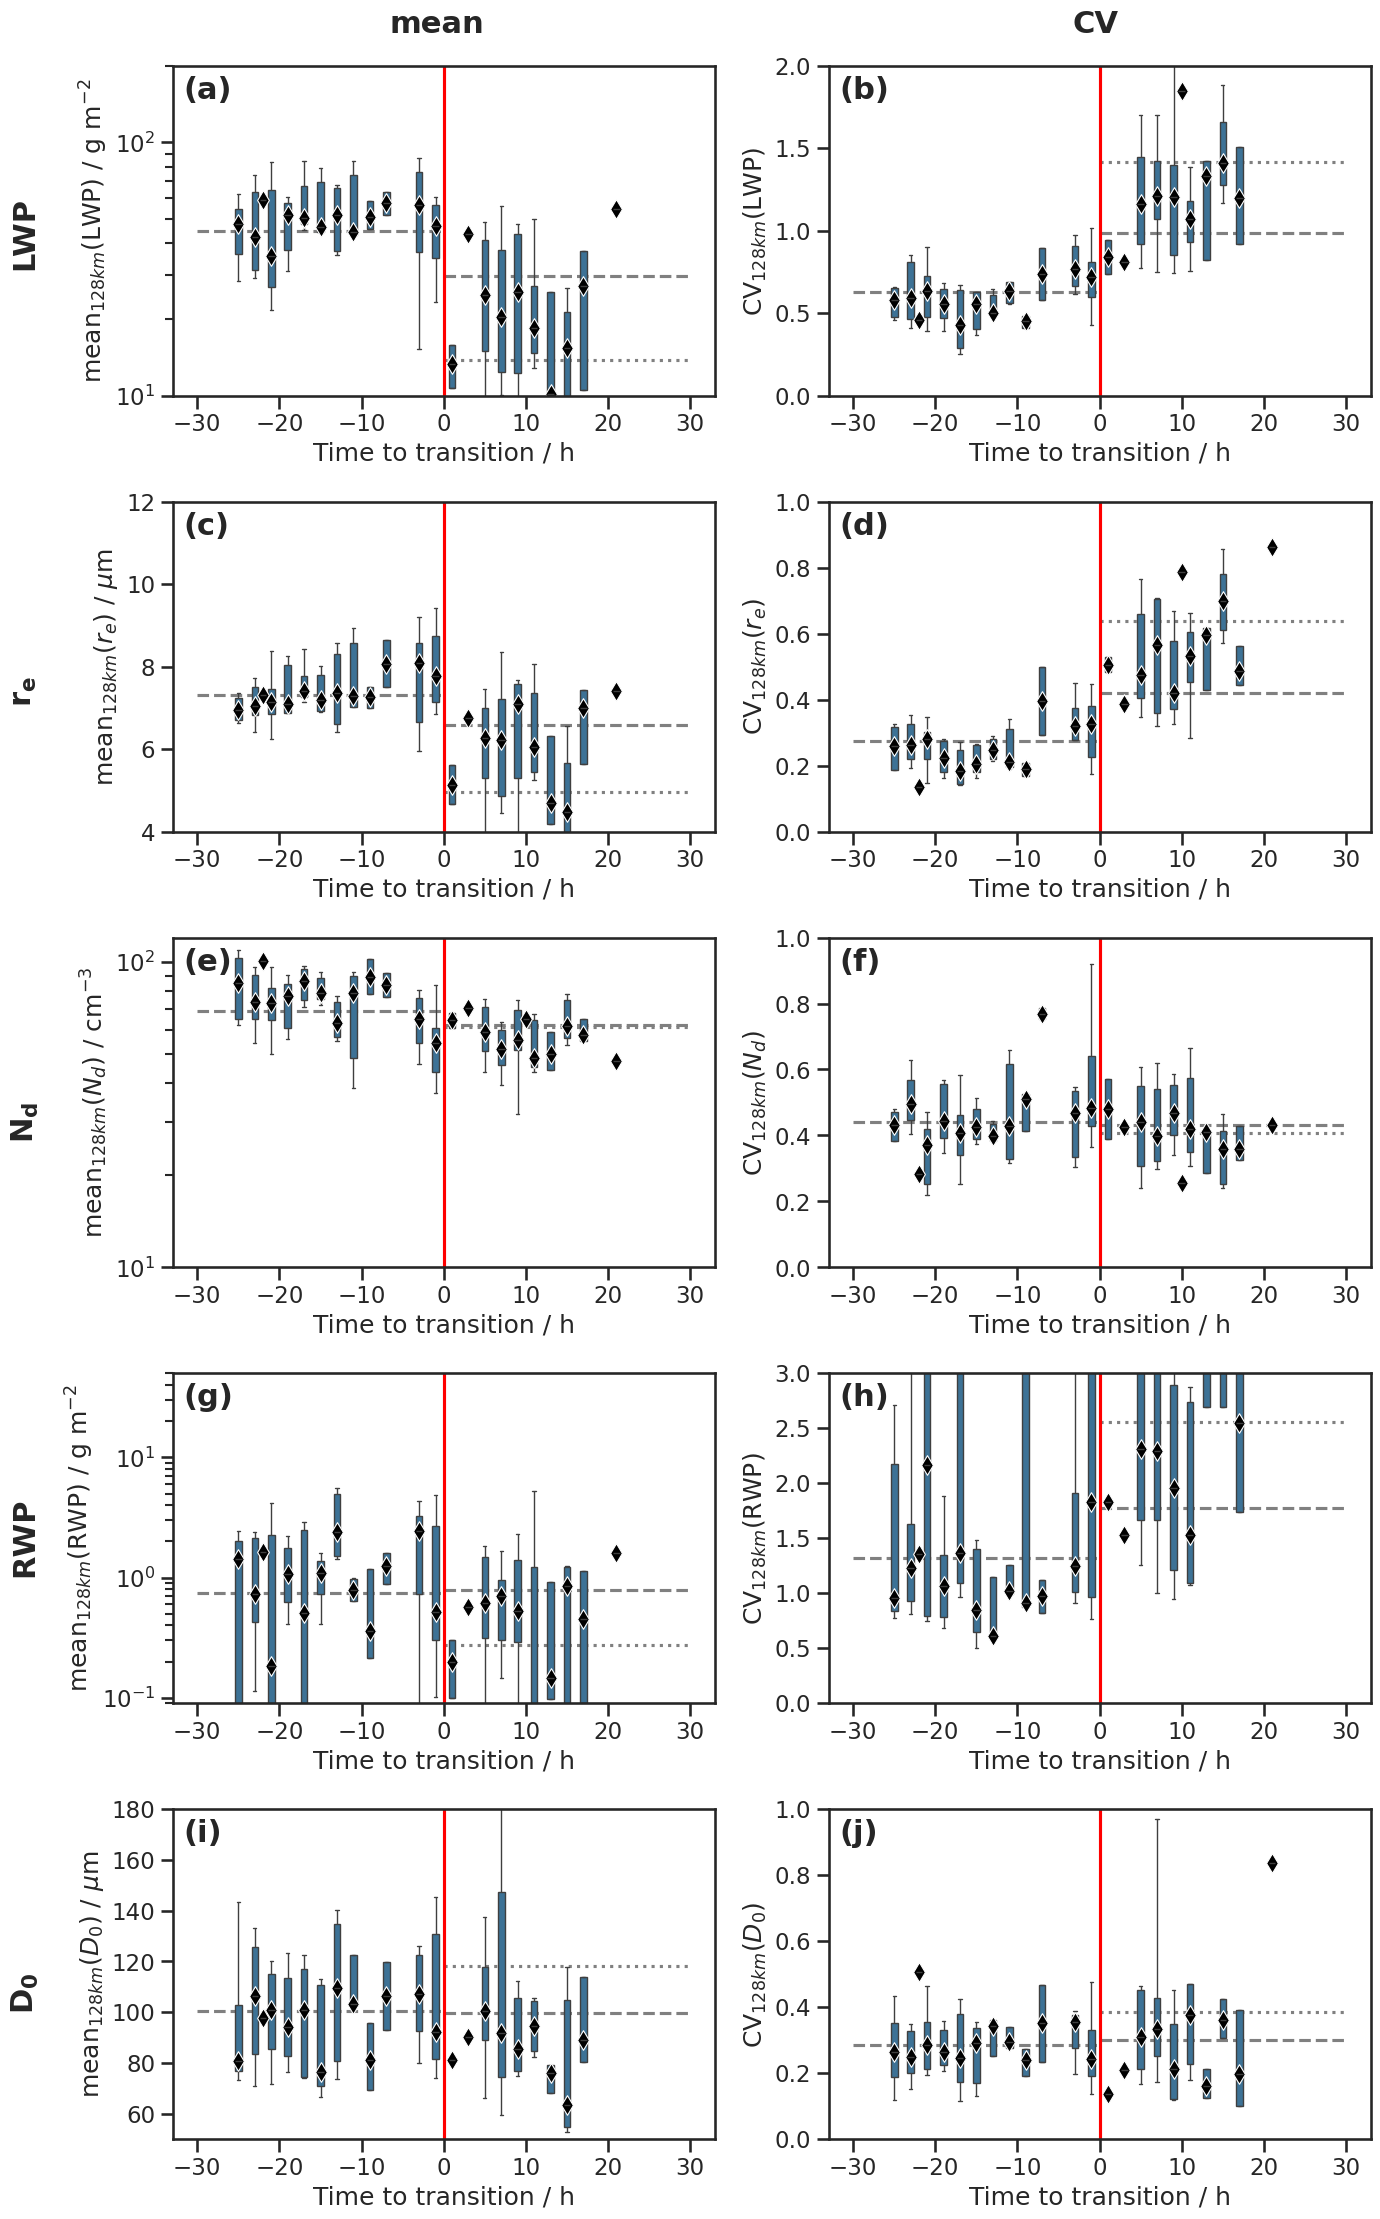

In [89]:
plot_params = {
    'lwp': {'factor': 1e3, 'y_label': 'mean$_{128km}$(LWP) / g m$^{-2}$', 'y_lim': (1e1, 2e2), 'y_scale': 'log'},
    'lwp_cv': {'factor': 1, 'y_label': 'CV$_{128km}$(LWP)', 'y_lim': (0, 2), 'y_scale': 'linear'},
    'ER': {'factor':1e6, 'y_label': 'mean$_{128km}$($r_e$) / $\mu$m', 'y_lim': (4, 12), 'y_scale': 'linear'},
    'ER_cv': {'factor':1, 'y_label': 'CV$_{128km}$($r_e$)', 'y_lim': (0, 1), 'y_scale': 'linear'},
    'Nd': {'factor': 1e-6, 'y_label': 'mean$_{128km}$($N_d$) / cm$^{-3}$', 'y_lim': (1e1, 1.2e2), 'y_scale': 'log'},
    'Nd_cv': {'factor': 1, 'y_label': 'CV$_{128km}$($N_d$)', 'y_lim': (0, 1), 'y_scale': 'linear'},
    'rwp': {'factor': 1e3, 'y_label': 'mean$_{128km}$(RWP) / g m$^{-2}$', 'y_lim': (9e-2, 5e1), 'y_scale': 'log'},
    'rwp_cv': {'factor': 1, 'y_label': 'CV$_{128km}$(RWP)', 'y_lim': (0, 3), 'y_scale': 'linear'},
    'rain_median_volume_diameter': {'factor':1e6, 'y_label': 'mean$_{128km}$($D_0$) / $\mu$m', 'y_lim': (5e1, 1.8e2), 'y_scale': 'linear'},
    'rain_median_volume_diameter_cv': {'factor':1, 'y_label': 'CV$_{128km}$($D_0$)', 'y_lim': (0, 1), 'y_scale': 'linear'},
}

sns.set_context('talk', font_scale=1.)
sns.set_style('white')
plt.rcParams['xtick.bottom'] = True
plt.rcParams['xtick.top'] = False
plt.rcParams['ytick.left'] = True
plt.rcParams['ytick.right'] = False

nrows = 5
fig, axs = plt.subplots(nrows, 2, figsize=(14, nrows*4.5))
axs = axs.flatten()

for i, (var, params) in enumerate(plot_params.items()):
    plt.sca(axs[i])
    if var == 'no_plot':
        axs[i].axis('off')
        continue
    plt.hlines(acmcap_climatology_median[var].sel(cats=1)*params['factor'], xmin=-30, xmax=0, color='grey', linestyle='--')
    plt.hlines(acmcap_climatology_median[var].sel(cats=3)*params['factor'], xmin=0, xmax=30, color='grey', linestyle='--')
    plt.hlines(acmcap_climatology_median[var].sel(cats=4)*params['factor'], xmin=0, xmax=30, color='grey', linestyle=':')
    sns.boxplot(data = bt_cd_concat, x='transition_time_diff', y=bt_cd_concat[var]*params['factor'], whis=(10, 90), native_scale=True, showfliers=False, saturation=0.6)
    tmp = bt_cd_concat[['transition_time_diff', var]].groupby('transition_time_diff').median()
    sns.scatterplot(data=tmp, x='transition_time_diff', y=tmp[var]*params['factor'], color='black', marker='d', s=100, zorder=2)
    
    plt.yscale(params['y_scale'])
    plt.ylim(params['y_lim'])
    plt.xlabel('Time to transition / h')
    plt.ylabel(params['y_label'])
    plt.axvline(0, color='red', linestyle='-')

axs[0].annotate('mean', xy=(0.4, 1.1), xycoords='axes fraction', fontsize=22, fontweight='bold')
axs[1].annotate('CV', xy=(0.45, 1.1), xycoords='axes fraction', fontsize=22, fontweight='bold')
for idx, text in enumerate(['(a)','(b)','(c)','(d)','(e)','(f)','(g)','(h)','(i)','(j)']):
    axs[idx].annotate(text, xy=(0.02, 0.9), xycoords='axes fraction', fontsize=22, fontweight='bold')

for idx, text in enumerate(['LWP','$\mathbf{r_e}$','$\mathbf{N_d}$','RWP','$\mathbf{D_0}$']):
    axs[idx*2].annotate(text, xy=(-0.3, 0.4), xycoords='axes fraction', rotation=90, fontsize=22, fontweight='bold')
fig.tight_layout()

/home/jmayer/miniconda3/envs/bt_env/lib/python3.13/site-packages/xarray/structure/concat.py:540: UserWarning: No index created for dimension transition_time_diff because variable transition_time_diff is not a coordinate. To create an index for transition_time_diff, please first call `.set_coords('transition_time_diff')` on this object.
  ds.expand_dims(dim_name, create_index_for_new_dim=create_index_for_new_dim)
/home/jmayer/miniconda3/envs/bt_env/lib/python3.13/site-packages/xarray/structure/concat.py:540: UserWarning: No index created for dimension transition_time_diff because variable transition_time_diff is not a coordinate. To create an index for transition_time_diff, please first call `.set_coords('transition_time_diff')` on this object.
  ds.expand_dims(dim_name, create_index_for_new_dim=create_index_for_new_dim)
/home/jmayer/miniconda3/envs/bt_env/lib/python3.13/site-packages/xarray/structure/concat.py:540: UserWarning: No index created for dimension transition_time_diff becaus

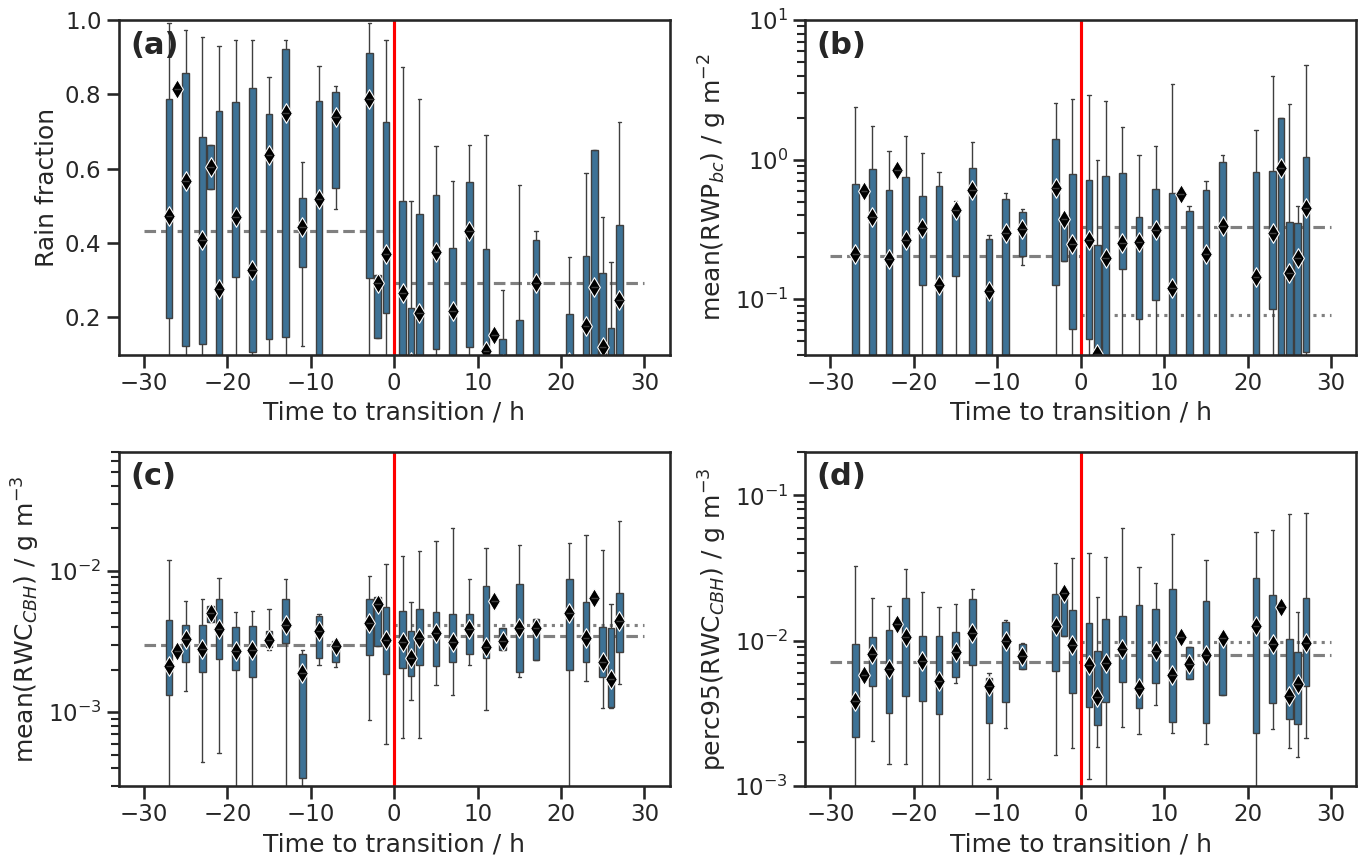

In [42]:
plot_params = {
    'rain_fraction': {'factor': 1, 'y_label': 'Rain fraction', 'y_lim': (0.1,1), 'y_scale': 'linear'},
    'rwp_subcloud': {'factor': 1e3, 'y_label': 'mean(RWP$_{bc}$) / g m$^{-2}$', 'y_lim': (4e-2, 1e1), 'y_scale': 'log'},
    'rwc_cbh': {'factor': 1e3, 'y_label': 'mean(RWC$_{CBH}$) / g m$^{-3}$', 'y_lim': (3e-4, 7e-2), 'y_scale': 'log'},
    'rwc_cbh_perc95': {'factor': 1e3, 'y_label': 'perc95(RWC$_{CBH}$) / g m$^{-3}$', 'y_lim': (1e-3, 2e-1), 'y_scale': 'log'},
}

sns.set_context('talk', font_scale=1.)
sns.set_style('white')
plt.rcParams['xtick.bottom'] = True
plt.rcParams['xtick.top'] = False
plt.rcParams['ytick.left'] = True
plt.rcParams['ytick.right'] = False

nrows = 2
fig, axs = plt.subplots(nrows, 2, figsize=(14, nrows*4.5))
axs = axs.flatten()

for i, (var, params) in enumerate(plot_params.items()):
    plt.sca(axs[i])
    if var == 'no_plot':
        axs[i].axis('off')
        continue
    plt.hlines(acmcap_climatology_median[var].sel(cats=1)*params['factor'], xmin=-30, xmax=0, color='grey', linestyle='--')
    plt.hlines(acmcap_climatology_median[var].sel(cats=3)*params['factor'], xmin=0, xmax=30, color='grey', linestyle='--')
    plt.hlines(acmcap_climatology_median[var].sel(cats=4)*params['factor'], xmin=0, xmax=30, color='grey', linestyle=':')
    sns.boxplot(data = bt_cd_concat, x='transition_time_diff', y=bt_cd_concat[var]*params['factor'], whis=(5, 95), native_scale=True, showfliers=False, saturation=0.6)
    tmp = bt_cd_concat[['transition_time_diff', var]].groupby('transition_time_diff').median()
    sns.scatterplot(data=tmp, x='transition_time_diff', y=tmp[var]*params['factor'], color='black', marker='d', s=100, zorder=2)
    
    plt.yscale(params['y_scale'])
    plt.ylim(params['y_lim'])
    plt.xlabel('Time to transition / h')
    plt.ylabel(params['y_label'])
    plt.axvline(0, color='red', linestyle='-')

for idx, text in enumerate(['(a)','(b)','(c)','(d)']):
    axs[idx].annotate(text, xy=(0.02, 0.9), xycoords='axes fraction', fontsize=22, fontweight='bold')

fig.tight_layout()

## examples of transitioning clouds

### time evolution of examples

In [43]:
sys.path.append('./../../../ectools/')
from ectools import ecio
from ectools import colormaps
sys.path.append('/home/jmayer/ACI_research/Code/mesoscale_structure/')
import access_ec_on_maap as maap

def get_CFMR_for_scene(orbit, lat_min, lat_max):
    # load C-FMR
    CFMR_list = maap.get_cfmr_via_maap(
                        frame=orbit[-1],
                        orbitNumber=orbit[:-1],
                        max_items=1,
                        )
    CFMR = CFMR_list[0][0]
    CFMR = CFMR.assign_coords(along_track=("along_track", CFMR.along_track.data))
    CFMR = CFMR.assign_coords(height_coord=("CPR_height", CFMR.height.isel(along_track=0).data))
    CFMR = CFMR.where((CFMR.latitude > lat_min) & (CFMR.latitude < lat_max), drop=True)
    CFMR = CFMR.swap_dims({'CPR_height': 'height_coord'})
    CFMR = CFMR.where(CFMR.height_coord > -500, drop=True)
    return CFMR

def get_ACMCAP_for_scene(orbit, lat_min, lat_max):
    # load ACMCAP
    ACMCAP_list = maap.get_acmcap_via_maap(
                            frame=orbit[-1],
                            orbitNumber=orbit[:-1],
                            max_items=1,
                            )
    ACMCAP = ACMCAP_list[0][0]
    encoding = ACMCAP.encoding
    ACMCAP = ACMCAP.where((ACMCAP.latitude > lat_min) & (ACMCAP.latitude < lat_max), drop=True)
    ACMCAP.encoding = encoding.copy()
    ACMCAP = ACMCAP.assign_coords(height_coord=("JSG_height", ACMCAP.height.isel(along_track=0).data))
    ACMCAP = ACMCAP.swap_dims({'JSG_height': 'height_coord'})
    return ACMCAP

def make_examples_along_time_plot(bt_cd_concat, variable_to_plot='reflectivity_no_attenuation_correction', vmin=-30, vmax=0, norm=None):
    fig = plt.figure(figsize=(50, 8))
    # Track occupied positions to avoid overlaps
    occupied_positions = []  # List of (left, right, bottom, top) rectangles
    max_number_of_plots_per_time = 6
    subplot_width = 0.025
    subplot_height = 1 / max_number_of_plots_per_time * 0.9  # Use 90% of vertical space for subplots

    time_min, time_max = -30, 30

    sns.set_context('talk', font_scale=0.8)

    bt_tmp = bt_cd_concat.where(bt_cd_concat.transition_flag == 1, drop=True)


    for i, dt_ in enumerate(np.unique(bt_tmp.transition_time_diff.values)):
        print(dt_)
        bt_tmp_dt = bt_tmp.where(bt_tmp.transition_time_diff == dt_, drop=True)
        number_of_plots = min(max_number_of_plots_per_time, len(bt_tmp_dt.time_startpoint.values))
        rng = np.random.RandomState(42)
        chosen_time_startpoints = rng.choice(bt_tmp_dt.time_startpoint.values, size=number_of_plots, replace=False)

        for t_ in chosen_time_startpoints:
            bt_tmp_t = bt_tmp.sel(time_startpoint=t_)
            orbit, lat_min, lat_max = bt_tmp_t.orbit.values, bt_tmp_t.lat_min.values, bt_tmp_t.lat_max.values

            if variable_to_plot in ['reflectivity_no_attenuation_correction']:
                ec_scene = get_CFMR_for_scene(str(orbit), lat_min, lat_max)
                cmap=colormaps.chiljet2
            else:
                ec_scene = get_ACMCAP_for_scene(str(orbit), lat_min, lat_max)
                cmap='turbo'
            
            # Calculate normalized x position
            norm_x = (dt_ - time_min) / (time_max - time_min)
            left = 0.05 + norm_x * 0.9  # Use 90% of figure width
            right = left + subplot_width
            
            # Find available vertical position
            bottom = 0.1  # Start from bottom
            found_position = False
            
            while not found_position:
                top = bottom + subplot_height
                
                # Check if this position overlaps with any existing subplot
                overlaps = False
                for occupied in occupied_positions:
                    occ_left, occ_right, occ_bottom, occ_top = occupied
                    
                    # Check for overlap
                    if (left < occ_right and right > occ_left and 
                        bottom < occ_top and top > occ_bottom):
                        overlaps = True
                        break
                
                if not overlaps:
                    found_position = True
                else:
                    bottom += subplot_height + 0.005  # Move up with small gap
            
            # Record this position as occupied
            occupied_positions.append((left, right, bottom, top))
            
            # Create the subplot
            ax = fig.add_axes([left, bottom, subplot_width, subplot_height])

            img = ec_scene[variable_to_plot].T.plot(ax=ax, cmap=cmap, vmin=vmin, vmax=vmax, ylim=(0,3000), add_colorbar=False, norm=norm)
            
            ax.set_axis_off()  # Turn off axis for small plots

    # add vertical line at transition time
    norm_x = (0 - time_min) / (time_max - time_min)
    plt.vlines(x=0.05 + norm_x * 0.9, ymin=0, ymax=1, color='red', linestyle='-', lw=3 )

    #max_y_position = np.max([occupied_positions[i][1] for i in range(len(occupied_positions))])
    ax = fig.add_axes([0.95, 0.5, 0.02, 0.2])  # Position for colorbar
    plt.colorbar(img, ax=ax, label=f'{variable_to_plot}')
    ax.set_axis_off()

    # plot one big time arrow at the bottom to indicate time axis
    ax = fig.add_axes([0.05, 0.05, 0.95, 0.02])  # Position for time axis
    ax.arrow(0, 0.5, 1, 0, head_width=0.03, head_length=0.02, length_includes_head=True, fc='black', ec='black')
    ax.text(0, 0.48, f'{time_min} h', ha='center')
    ax.text(1, 0.48, f'{time_max} h', ha='center')
    ax.text(0.5, 0.48, f'transition', ha='center')
    ax.set_axis_off()
    #plt.savefig(f'./figures/examples_vs_time_{variable_to_plot}.png', dpi=300)

In [ ]:
make_examples_along_time_plot(bt_cd_concat, variable_to_plot='reflectivity_no_attenuation_correction', vmin=-30, vmax=0)

In [ ]:
make_examples_along_time_plot(bt_cd_concat, variable_to_plot='rain_water_content', vmin=1e-7, vmax=1e-3, norm=LogNorm())

-27.0
Accessing 1 items (limited by max_items).
1 items found that matched the query.
Found .h5 file in enclosure_h5: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/ACM_CAP_2B/BA/2025/05/11/ECA_EXBA_ACM_CAP_2B_20250511T190709Z_20250918T052929Z_05412E/ECA_EXBA_ACM_CAP_2B_20250511T190709Z_20250918T052929Z_05412E/ECA_EXBA_ACM_CAP_2B_20250511T190709Z_20250918T052929Z_05412E.h5
HDF5 URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/ACM_CAP_2B/BA/2025/05/11/ECA_EXBA_ACM_CAP_2B_20250511T190709Z_20250918T052929Z_05412E/ECA_EXBA_ACM_CAP_2B_20250511T190709Z_20250918T052929Z_05412E/ECA_EXBA_ACM_CAP_2B_20250511T190709Z_20250918T052929Z_05412E.h5
Orbit: 05412E
Fetching ESA MAAP token...
p1eL7uonXs6MDxtGbgKdPVRAmnGxHpVE
Dataset URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/ACM_CAP_2B/BA/2025/05/11/ECA_EXBA_ACM_CAP_2B_20250511T190709Z_20250918T052929Z_05412E/ECA_EXBA_ACM_CAP_2B_20250511T190709Z_20250918T052929Z_05412E/ECA_EXBA_ACM_CAP_2B_2

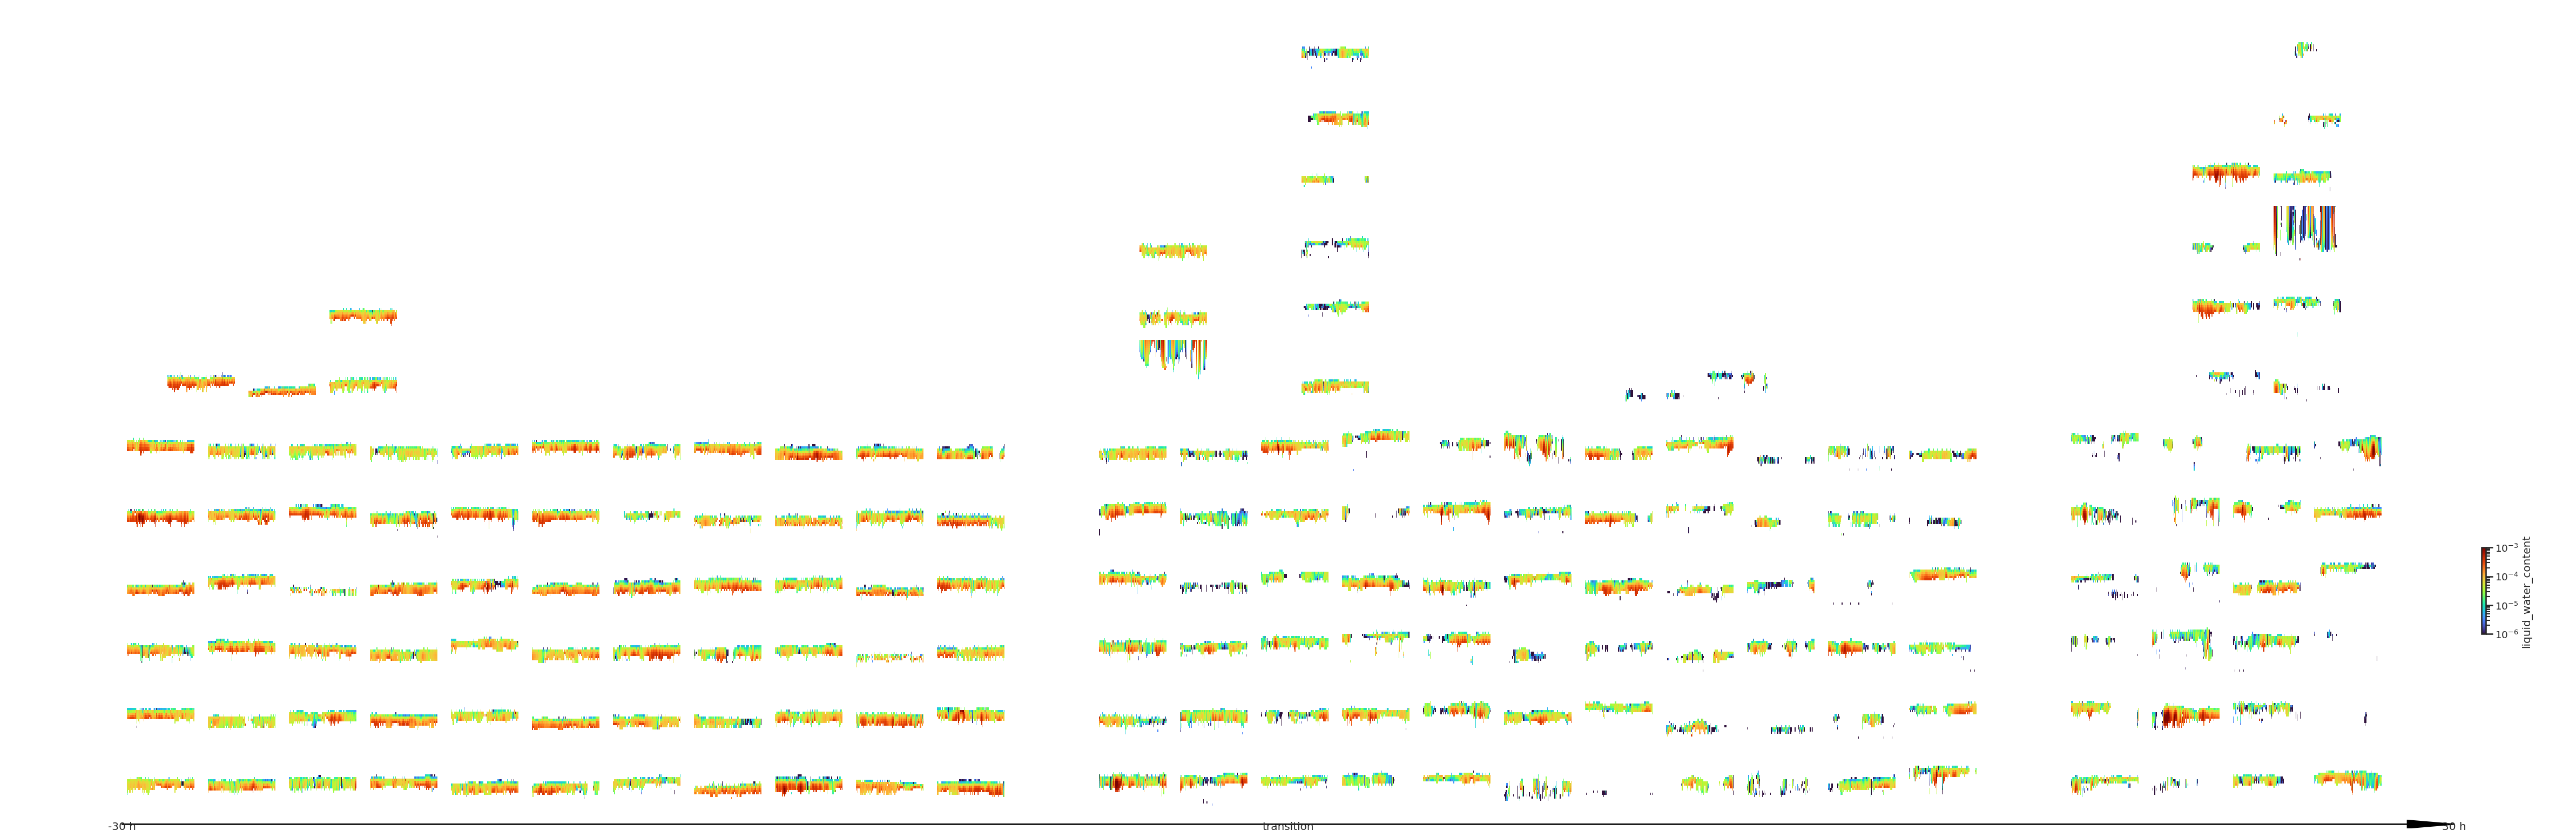

In [44]:
make_examples_along_time_plot(bt_cd_concat, variable_to_plot='liquid_water_content', vmin=1e-6, vmax=1e-3, norm=LogNorm())